# Reproducibility notebook — *A Phase-Space Geometric Measure of Magic in Qubit Systems*

S. Dutta, Tushar, H. Ma and W. Zhang, arXiv:2603.20792 (version 7, October 2026).

This notebook recomputes every numerical claim in the revised paper, checks every closed-form
result and every explicit certificate against linear programming over the complete stabilizer polytope (floating point, HiGHS),
re-checks the rational certificates of Remark 5.6 and Appendix D in exact arithmetic, and **generates all seven
figures as PDF files** in `figures/`, ready to upload to Overleaf. Each check is recorded in a
ledger printed at the end (Section 14). Section and theorem numbers below refer to the revised paper.

**Conventions** (as in the paper)
* Single-qubit Wootters phase-point operators
  $A_{(q,p)} = \tfrac12\bigl(I + (-1)^p X + (-1)^{q+p} Y + (-1)^q Z\bigr)$,
  $n$-qubit operators are tensor products, and $W_\rho(\alpha)=\mathrm{Tr}(\rho A_\alpha)/2^n$.
* $C(\rho)=\min_{\sigma\in\mathrm{conv}(\mathrm{STAB}_n)}\lVert W_\rho-W_\sigma\rVert_1$ (linear program).
* $\Gamma(\rho)$ is the robustness of magic, $\kappa=(\Gamma-1)/C$.
* Families: $|\psi^{Ry}_\theta\rangle=\cos\tfrac\theta2|0^n\rangle+\sin\tfrac\theta2|1^n\rangle$,
  $|\psi^{Rx}_\theta\rangle=\cos\tfrac\theta2|0^n\rangle-i\sin\tfrac\theta2|1^n\rangle$,
  $|\Phi_\theta\rangle=(|0^n\rangle+e^{i\theta}|1^n\rangle)/\sqrt2$; logical operators
  $X_L=X^{\otimes n}$, $Y_L=Y\otimes X^{\otimes(n-1)}$, $Z_L=Z\otimes I^{\otimes(n-1)}$.
* Witness normalization (Theorem 3.3): a Hermitian $H$ certifies
  $C(\rho)\ge 2^{-n}[\mathrm{Tr}(H\rho)-\max_\sigma\mathrm{Tr}(H\sigma)]$ only if
  $|\mathrm{Tr}(HA_\alpha)|\le 2^n$ for all $\alpha$. All witness checks below enforce this.

**Runtime.** With `RUN_N4 = RUN_SLOW = False` the notebook runs in about two minutes.
`RUN_N4` adds the four-qubit linear programs (36,720 stabilizer states; a few minutes).
`RUN_SLOW` adds the frame-census maxima and multistart searches (about 10 minutes).
`MAKE_FIGURES` writes the figure PDFs (about one minute).

**Requirements.** Python ≥ 3.9, `numpy`, `scipy` (HiGHS, ≥ 1.9), `matplotlib`.

In [1]:
RUN_N4       = True    # four-qubit LPs (Sections 1.1, 10)
RUN_SLOW     = True    # frame-census maxima and multistart searches (Sections 4, 11)
MAKE_FIGURES = True    # write figures/fig_*.pdf (Section 13)

import numpy as np, itertools, time, collections, os
from scipy.optimize import linprog, minimize
from scipy import sparse
np.set_printoptions(precision=6, suppress=True, linewidth=110)
T0 = time.time()

LEDGER = []
def check(name, ok, detail=""):
    # Record a check in the ledger and print it.
    ok = bool(ok)
    LEDGER.append((name, ok, detail))
    print(f"[{'PASS' if ok else 'FAIL'}] {name}" + (f"  —  {detail}" if detail else ""))

def close(a, b, tol=1e-7):
    return abs(a - b) <= tol

## 1. Machinery: phase-point operators, stabilizer states, and the two linear programs

In [2]:
I2 = np.eye(2, dtype=complex)
X  = np.array([[0, 1], [1, 0]], dtype=complex)
Y  = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z  = np.diag([1, -1]).astype(complex)
Hd = (X + Z) / np.sqrt(2)
Sg = np.diag([1, 1j]).astype(complex)
P1 = [I2, X, Y, Z]
PAULI = {'I': I2, 'X': X, 'Y': Y, 'Z': Z}

def kron_all(ops):
    out = np.array([[1]], dtype=complex)
    for o in ops:
        out = np.kron(out, o)
    return out

def pauli(label):
    return kron_all([PAULI[c] for c in label])

def A1q(q, p, a=(1, 1, 1)):
    # Single-qubit phase-point operator; a=(a_x,a_y,a_z) selects one of the 8 valid origins.
    return 0.5 * (I2 + a[0] * (-1)**p * X + a[1] * (-1)**(q + p) * Y + a[2] * (-1)**q * Z)

PTS = [(0, 0), (0, 1), (1, 0), (1, 1)]
A1 = [A1q(q, p) for q, p in PTS]                        # order (q,p) = 00, 01, 10, 11

def phase_points(n, single=None):
    single = A1 if single is None else single
    return [kron_all(t) for t in itertools.product(single, repeat=n)]

def wigner_matrix(Aops):
    # Matrix M with W = Re(M @ vec(rho)) / dim.
    return np.array([A.T.reshape(-1) for A in Aops])

def proj(v):
    v = np.asarray(v, dtype=complex); v = v / np.linalg.norm(v)
    return np.outer(v, v.conj())

def bloch(r):
    return 0.5 * (I2 + r[0] * X + r[1] * Y + r[2] * Z)

def stabilizer_states(n):
    # All pure n-qubit stabilizer states, as the orbit of |0..0> under H, S and CNOT.
    dim = 2**n
    gates = []
    for i in range(n):
        for g in (Hd, Sg):
            ops = [I2] * n; ops[i] = g; gates.append(kron_all(ops))
    for c, t in itertools.permutations(range(n), 2):
        M = np.zeros((dim, dim), dtype=complex)
        for b in range(dim):
            bits = [(b >> (n - 1 - k)) & 1 for k in range(n)]
            if bits[c]: bits[t] ^= 1
            M[int(''.join(map(str, bits)), 2), b] = 1
        gates.append(M)
    def key(v):
        i = np.flatnonzero(np.abs(v) > 1e-9)[0]
        v = v * (abs(v[i]) / v[i])
        return tuple(np.round(np.concatenate([v.real, v.imag]), 7))
    start = np.zeros(dim, dtype=complex); start[0] = 1
    seen = {key(start): start}; frontier = [start]
    while frontier:
        nxt = []
        for v in frontier:
            for g in gates:
                w = g @ v; k = key(w)
                if k not in seen:
                    seen[k] = w; nxt.append(w)
        frontier = nxt
    return np.array(list(seen.values()))

class Magic:
    # C and Gamma for n qubits in a given frame (default: Wootters product frame).
    def __init__(self, n, Aops=None, states=None):
        self.n = n; self.dim = 2**n
        self.Aops = phase_points(n) if Aops is None else Aops
        self.M = wigner_matrix(self.Aops)
        self.psi = stabilizer_states(n) if states is None else states
        R = np.einsum('si,sj->sij', self.psi, self.psi.conj()).reshape(len(self.psi), -1)
        self.Ws = (R @ self.M.T).real / self.dim                 # (N_stab, 4^n)
        self.N, self.d = self.Ws.shape
        Wt = sparse.csr_matrix(self.Ws.T); Id = sparse.identity(self.d, format='csr')
        self.cC = np.r_[np.zeros(self.N), np.ones(self.d)]
        self.AubC = sparse.vstack([sparse.hstack([-Wt, -Id]), sparse.hstack([Wt, -Id])]).tocsr()
        self.AeqC = sparse.csr_matrix(np.r_[np.ones(self.N), np.zeros(self.d)][None, :])
        self.AeqG = sparse.hstack([Wt, -Wt]).tocsr()
    def W(self, rho):
        return (self.M @ np.asarray(rho).reshape(-1)).real / self.dim
    def C(self, rho, witness=False):
        w0 = self.W(rho)
        r = linprog(self.cC, A_ub=self.AubC, b_ub=np.r_[-w0, w0], A_eq=self.AeqC, b_eq=[1],
                    bounds=(0, None), method='highs')
        assert r.status == 0, r.message
        if not witness:
            return r.fun
        m = r.ineqlin.marginals; y = m[:self.d] - m[self.d:]
        for cand in (y, -y):
            if close(cand @ w0 - (self.Ws @ cand).max(), r.fun, 1e-6):
                return r.fun, cand
        return r.fun, None
    def Gamma(self, rho):
        w0 = self.W(rho)
        r = linprog(np.ones(2 * self.N), A_eq=self.AeqG, b_eq=w0, bounds=(0, None), method='highs')
        assert r.status == 0, r.message
        return r.fun
    def M_n(self):
        return np.abs(self.Ws).sum(1).max()
    def stab_max(self, H):
        # max over pure stabilizer states of Tr(H sigma)
        return np.real(np.einsum('si,ij,sj->s', self.psi.conj(), H, self.psi)).max()
    def certified(self, H, rho):
        # Best bound certified by the direction H (Theorem 3.3): rescale H so that
        # max_alpha |Tr(H A_alpha)| = 2^n. Returns (bound, max_alpha |Tr(H A_alpha)|).
        t = np.array([np.trace(H @ A).real for A in self.Aops]); mu = np.abs(t).max()
        return (np.trace(H @ rho).real - self.stab_max(H)) / mu, mu
    def C_restricted(self, rho, labels):
        # Dual LP for C with the witness operator restricted to span{Pauli(l) : l in labels}.
        B = np.array([[np.trace(pauli(l) @ A).real for l in labels] for A in self.Aops]) / self.dim
        w = self.W(rho)
        A_ub = np.vstack([np.c_[self.Ws @ B, -np.ones(self.N)], np.c_[B, np.zeros(len(B))],
                          np.c_[-B, np.zeros(len(B))]])
        r = linprog(np.r_[-(B.T @ w), 1.0], A_ub, np.r_[np.zeros(self.N), np.ones(2 * len(B))],
                    bounds=(None, None), method='highs')
        return -r.fun

def fam(name, th, n=2):
    z = np.zeros(2**n, dtype=complex); o = np.zeros(2**n, dtype=complex); z[0] = 1; o[-1] = 1
    if name == 'Ry':  return proj(np.cos(th/2) * z + np.sin(th/2) * o)
    if name == 'Rx':  return proj(np.cos(th/2) * z - 1j * np.sin(th/2) * o)
    if name == 'BRz': return proj(z + np.exp(1j * th) * o)

def logical_ops(n):
    return (kron_all([X]*n), kron_all([Y] + [X]*(n-1)), kron_all([Z] + [I2]*(n-1)))

C1closed = lambda r: max(0.0, (np.abs(r).sum() - 1) / 2)          # Proposition 4.3
s_of = lambda r: 0 if abs(np.prod(r)) < 1e-12 else int(np.sign(np.prod(r)))

expected_counts = {1: 6, 2: 60, 3: 1080, 4: 36720}
MAG = {}
for n in (1, 2, 3):
    t = time.time(); MAG[n] = Magic(n)
    check(f"number of {n}-qubit stabilizer states = {expected_counts[n]}",
          MAG[n].N == expected_counts[n], f"found {MAG[n].N} ({time.time()-t:.1f}s)")
if RUN_N4:
    t = time.time(); MAG[4] = Magic(4)
    check("number of 4-qubit stabilizer states = 36720", MAG[4].N == 36720,
          f"found {MAG[4].N} ({time.time()-t:.1f}s)")
M1, M2, M3 = MAG[1], MAG[2], MAG[3]
W1, W2 = M1.W, M2.W
rng = np.random.default_rng(2603)
def rand_pure(dim):
    v = rng.normal(size=dim) + 1j * rng.normal(size=dim); return proj(v)
def rand_mixed(dim, rank=None):
    rank = dim if rank is None else rank
    G = rng.normal(size=(dim, rank)) + 1j * rng.normal(size=(dim, rank)); r = G @ G.conj().T
    return r / np.trace(r).real
def rand_bloch(pure=False):
    v = rng.normal(size=3); v /= np.linalg.norm(v)
    return v if pure else v * rng.uniform(0, 1) ** (1/3)

[PASS] number of 1-qubit stabilizer states = 6  —  found 6 (0.0s)
[PASS] number of 2-qubit stabilizer states = 60  —  found 60 (0.0s)


[PASS] number of 3-qubit stabilizer states = 1080  —  found 1080 (0.3s)


[PASS] number of 4-qubit stabilizer states = 36720  —  found 36720 (13.2s)


### 1.1 Basic Wigner facts (Sections 2.3–2.4, 3.1, Theorem 3.2, Lemma 4.7, Appendix C)

In [3]:
check("M_1 = 1", close(M1.M_n(), 1))
check("M_2 = 2 (attained by Bell states)", close(M2.M_n(), 2))
check("M_3 = 5/2", close(M3.M_n(), 2.5))
if RUN_N4:
    check("M_4 = 4", close(MAG[4].M_n(), 4))
bell = proj([1, 0, 0, 1])
WBB = np.kron(W2(bell), W2(bell))
if RUN_N4:
    check("Wigner factorization: W_{Bell⊗Bell} = W_Bell ⊗ W_Bell", np.allclose(MAG[4].W(np.kron(bell, bell)), WBB))
check("Section 3.1: M_{n+m} >= M_n M_m, e.g. ||W_{Bell⊗Bell}||_1 = 4 = M_2^2", close(np.abs(WBB).sum(), 4))
check("Section 2.4: Bell-state Wigner entries reach -1/8, so W_free(2) is not inside the orthant",
      close(W2(bell).min(), -1/8) and close(M2.Ws.min(), -1/8))
check("Lemma 4.7: every single-qubit stabilizer Wigner vector has entries in {0, 1/2}",
      np.all(np.isclose(M1.Ws, 0) | np.isclose(M1.Ws, .5)))
check("Thm 3.2(i): C vanishes on stabilizer mixtures, e.g. C(I/4) = 0 and C(random mixture) = 0",
      close(M2.C(np.eye(4) / 4), 0, 1e-9) and
      close(M2.C(sum(w * np.outer(p, p.conj()) for w, p in zip(rng.dirichlet(np.ones(5)), M2.psi[:5]))), 0, 1e-9))
samples = [W2(rand_pure(4)) for _ in range(20000)]
wmin = min(w.min() for w in samples); wmax = max(w.max() for w in samples)
negcount = collections.Counter(int((w < -1e-12).sum()) for w in samples)
ev = np.linalg.eigvalsh(np.kron(A1[0], A1[0]))
check("eigenvalues of a two-qubit A_alpha are -1/2, -1/2, (2-√3)/2, (2+√3)/2",
      np.allclose(sorted(ev), sorted([-.5, -.5, (2-3**.5)/2, (2+3**.5)/2])))
check("Prop C.1(2): -1/8 <= W <= (2+√3)/8 on 20,000 random pure states",
      wmin >= -1/8 - 1e-12 and wmax <= (2+3**.5)/8 + 1e-12, f"observed range [{wmin:.4f}, {wmax:.4f}]")
check("Prop C.1(3): sum W^2 = 1/4 for pure states",
      all(close((w**2).sum(), .25, 1e-10) for w in samples[:500]))
print("   number of negative entries over random pure two-qubit states:", dict(sorted(negcount.items())))
check("Appendix C: random pure states reach 9 negative entries", max(negcount) >= 9, f"maximum seen {max(negcount)}")
chi_ok = all(close(np.trace(pauli('XYZ') @ np.kron(r1, r2)).real,
                   np.trace(pauli('XY') @ r1).real * np.trace(Z @ r2).real, 1e-12)
             for r1, r2 in ((rand_mixed(4), rand_mixed(2)) for _ in range(20)))
check("Remark 2.1: the Pauli characteristic function factorizes on product states", chi_ok)

[PASS] M_1 = 1
[PASS] M_2 = 2 (attained by Bell states)
[PASS] M_3 = 5/2
[PASS] M_4 = 4
[PASS] Wigner factorization: W_{Bell⊗Bell} = W_Bell ⊗ W_Bell
[PASS] Section 3.1: M_{n+m} >= M_n M_m, e.g. ||W_{Bell⊗Bell}||_1 = 4 = M_2^2
[PASS] Section 2.4: Bell-state Wigner entries reach -1/8, so W_free(2) is not inside the orthant
[PASS] Lemma 4.7: every single-qubit stabilizer Wigner vector has entries in {0, 1/2}
[PASS] Thm 3.2(i): C vanishes on stabilizer mixtures, e.g. C(I/4) = 0 and C(random mixture) = 0


[PASS] eigenvalues of a two-qubit A_alpha are -1/2, -1/2, (2-√3)/2, (2+√3)/2
[PASS] Prop C.1(2): -1/8 <= W <= (2+√3)/8 on 20,000 random pure states  —  observed range [-0.1245, 0.4583]
[PASS] Prop C.1(3): sum W^2 = 1/4 for pure states
   number of negative entries over random pure two-qubit states: {1: 2, 2: 11, 3: 237, 4: 3162, 5: 8276, 6: 6645, 7: 1465, 8: 184, 9: 18}
[PASS] Appendix C: random pure states reach 9 negative entries  —  maximum seen 9
[PASS] Remark 2.1: the Pauli characteristic function factorizes on product states


## 2. The single-qubit metric: cuboctahedron = $A_3$ root polytope (Lemma 4.1, Remark 4.2)

In [4]:
Tset = np.array([t for t in itertools.product([1, -1], repeat=3) if np.prod(t) == 1])
vs = rng.normal(size=(20000, 3))
lhs = np.abs(vs @ Tset.T).sum(1) / 4
rhs = np.maximum(np.abs(vs).max(1), 0.5 * np.abs(vs).sum(1))
check("Lemma 4.1: ||W_rho - W_sigma||_1 = max(||v||_inf, ||v||_1/2) (20,000 random v)",
      np.allclose(lhs, rhs, atol=1e-12))
ok = True
for _ in range(500):
    r1, r2 = rand_bloch(), rand_bloch(); v = r1 - r2
    ok &= close(np.abs(W1(bloch(r1)) - W1(bloch(r2))).sum(), max(np.abs(v).max(), .5*np.abs(v).sum()), 1e-12)
check("Lemma 4.1 with actual single-qubit Wigner functions (500 pairs)", ok)
verts = [np.array(p) for p in set(itertools.permutations([1, 1, 0])) | set(itertools.permutations([1, -1, 0])) |
         set(itertools.permutations([-1, -1, 0])) | set(itertools.permutations([-1, 1, 0]))]
images = set()
for v in verts:
    dW = W1(bloch(np.zeros(3)) + 0.5 * (v[0]*X + v[1]*Y + v[2]*Z)) - W1(bloch(np.zeros(3)))
    images.add(tuple(np.round(dW * 2, 9)))
roots = {tuple(np.round(np.eye(4)[a] - np.eye(4)[b], 9)) for a in range(4) for b in range(4) if a != b}
check("Remark 4.2: the 12 vertices of K map exactly onto the A_3 roots (e_a - e_b)/2",
      len(verts) == 12 and images == roots)

[PASS] Lemma 4.1: ||W_rho - W_sigma||_1 = max(||v||_inf, ||v||_1/2) (20,000 random v)
[PASS] Lemma 4.1 with actual single-qubit Wigner functions (500 pairs)
[PASS] Remark 4.2: the 12 vertices of K map exactly onto the A_3 roots (e_a - e_b)/2


## 3. One qubit: the closed form and the maximum (Proposition 4.3, Theorem 4.4, Remark 4.5)
Proposition 4.3: $C(\rho)=\tfrac12\max(0,\lVert\vec r\rVert_1-1)$ for every qubit state;
at most one negative Wigner entry; $\lVert W_\rho\rVert_1-1\le C(\rho)$ with equality iff $C=0$ or
$s(\rho)=\mathrm{sgn}(r_xr_yr_z)\le0$; for $s>0$ the gap is $\min(\min_i|r_i|,\tfrac12(\lVert\vec r\rVert_1-1))$ (Section 5.3).

In [5]:
ok_cf = ok_neg = ok_eq = ok_gap = True; n_s_pos = n_s_nonpos = 0
for k in range(2000):
    r = rand_bloch(pure=(k % 2 == 0)); rho = bloch(r); C = M1.C(rho); W = W1(rho)
    ok_cf &= close(C, C1closed(r), 1e-9)
    ok_neg &= (W < -1e-12).sum() <= 1
    negmass = np.abs(W).sum() - 1
    inner = max(r @ u for u in -Tset)
    ok_eq &= close(negmass, max(0, inner - 1) / 2, 1e-9) and negmass <= C + 1e-9
    if C > 1e-9:
        if s_of(r) <= 0:
            n_s_nonpos += 1; ok_eq &= close(C, negmass, 1e-9)
        else:
            n_s_pos += 1; m = np.abs(r).min()
            ok_eq &= C - negmass > 1e-12 and close(inner, np.abs(r).sum() - 2 * m, 1e-9)
            ok_gap &= close(C - negmass, min(m, (np.abs(r).sum() - 1) / 2), 1e-9)
check("Prop 4.3: C = max(0, ||r||_1 - 1)/2 on 2,000 random pure and mixed states", ok_cf)
check("Prop 4.3: every single-qubit Wigner function has at most one negative entry", ok_neg)
check("Prop 4.3: ||W||_1 - 1 = max(0, max_{u in -T} <r,u> - 1)/2 <= C, equality iff s <= 0 (for C > 0)",
      ok_eq, f"{n_s_nonpos} magic states with s<=0, {n_s_pos} with s>0")
check("Section 5.3: for s > 0 the gap C - (||W||_1 - 1) = min(min|r_i|, (||r||_1-1)/2)", ok_gap)

c0 = (3**.5 - 1) / 2
faces = [np.array(s) / 3**.5 for s in itertools.product([1, -1], repeat=3)]
Cf = [M1.C(bloch(f)) for f in faces]
check("Thm 4.4: C = (√3-1)/2 at all eight face states", all(close(c, c0, 1e-9) for c in Cf))
best = max(M1.C(rand_pure(2)) for _ in range(3000))
check("Thm 4.4: no random pure single-qubit state exceeds (√3-1)/2 (3,000 samples)", best <= c0 + 1e-9, f"max {best:.9f}")
near = []
for f in faces:
    for _ in range(5):
        g = f + 0.05 * rng.normal(size=3); near.append(M1.C(bloch(g / np.linalg.norm(g))))
check("Thm 4.4: pure states near (not at) the faces are strictly below the maximum", max(near) < c0 - 1e-6)
rf = bloch(np.array([1, 1, -1]) / 3**.5); rg = bloch(np.array([1, 1, 1]) / 3**.5)
Gf = M1.Gamma(rf)
check("Remark 4.5: Gamma(rho_f) = √3 and kappa(rho_f) = 2", close(Gf, 3**.5, 1e-8) and close((Gf - 1) / M1.C(rf), 2, 1e-8))
rH = bloch(np.array([1, 1, 0]) / 2**.5)
check("Section 5.2: C(rho_H) = (√2-1)/2 for the H-type state T|+>", close(M1.C(rH), (2**.5 - 1) / 2, 1e-9))
check("Open problem (iv): (√3-1)/2 = -lambda_min(A_{+++})", close(-np.linalg.eigvalsh(A1q(0, 0)).min(), c0, 1e-12))

[PASS] Prop 4.3: C = max(0, ||r||_1 - 1)/2 on 2,000 random pure and mixed states
[PASS] Prop 4.3: every single-qubit Wigner function has at most one negative entry
[PASS] Prop 4.3: ||W||_1 - 1 = max(0, max_{u in -T} <r,u> - 1)/2 <= C, equality iff s <= 0 (for C > 0)  —  828 magic states with s<=0, 854 with s>0
[PASS] Section 5.3: for s > 0 the gap C - (||W||_1 - 1) = min(min|r_i|, (||r||_1-1)/2)
[PASS] Thm 4.4: C = (√3-1)/2 at all eight face states


[PASS] Thm 4.4: no random pure single-qubit state exceeds (√3-1)/2 (3,000 samples)  —  max 0.365829125
[PASS] Thm 4.4: pure states near (not at) the faces are strictly below the maximum
[PASS] Remark 4.5: Gamma(rho_f) = √3 and kappa(rho_f) = 2
[PASS] Section 5.2: C(rho_H) = (√2-1)/2 for the H-type state T|+>
[PASS] Open problem (iv): (√3-1)/2 = -lambda_min(A_{+++})


## 4. Products of single-qubit states (Proposition 4.8, Theorem 4.9, Proposition 4.11, Corollaries 4.13–4.14)
Theorem 4.9: $C(\rho_1\otimes\cdots\otimes\rho_k)\ge\prod_i\lVert W_{\rho_i}\rVert_1-1$ for all single-qubit factors
(certified by the product sign witness $S=s_1\otimes\cdots\otimes s_k$), with equality
$\prod_i(1+C(\rho_i))-1$ whenever every factor has $s\le0$ (or $C=0$).

In [6]:
viol = 0
for _ in range(300):
    a, b = rand_mixed(2, rng.integers(1, 3)), rand_mixed(2, rng.integers(1, 3))
    if M2.C(np.kron(a, b)) > (1 + M1.C(a)) * (1 + M1.C(b)) - 1 + 1e-8: viol += 1
check("Prop 4.8: C(rho⊗sigma) <= (1+C(rho))(1+C(sigma)) - 1 on 300 random pairs", viol == 0, f"{viol} violations")

signs = [np.ones(4)] + [np.where(np.arange(4) == k, -1., 1.) for k in range(4)]
mx2 = max((M2.Ws @ np.kron(a, b)).max() for a in signs for b in signs)
mx3 = max((M3.Ws @ kron_all([a[:, None], b[:, None], c[:, None]]).ravel()).max()
          for a in signs for b in signs for c in signs)
check("Thm 4.9: the 25 (k=2) and 125 (k=3) product sign witnesses have max exactly 1 over STAB",
      close(mx2, 1, 1e-12) and close(mx3, 1, 1e-12), f"{mx2:.12f}, {mx3:.12f}")

ok_low = ok_eq2 = ok_marg = True; n_eq = 0
for _ in range(200):
    a, b = rand_bloch(), rand_bloch()
    Cab = M2.C(np.kron(bloch(a), bloch(b)))
    ok_low &= Cab >= np.abs(W1(bloch(a))).sum() * np.abs(W1(bloch(b))).sum() - 1 - 1e-9
    ok_marg &= Cab >= max(C1closed(a), C1closed(b)) - 1e-9
    if s_of(a) <= 0 and s_of(b) <= 0:
        n_eq += 1; ok_eq2 &= close(Cab, (1 + C1closed(a)) * (1 + C1closed(b)) - 1, 1e-8)
check("Thm 4.9, Eq. (18): C(rho⊗sigma) >= ||W_rho||_1 ||W_sigma||_1 - 1 (200 random pairs, mixed included)", ok_low)
check("Thm 4.9: equality C = (1+C_rho)(1+C_sigma) - 1 whenever s(rho), s(sigma) <= 0", ok_eq2, f"{n_eq} pairs")
check("Remark 5.6 input: C(rho⊗sigma) >= max(C(rho), C(sigma)) (partial trace is l1-contractive)", ok_marg)
ok3 = True
for _ in range(10):
    rs = []
    while len(rs) < 3:
        r = rand_bloch()
        if s_of(r) <= 0: rs.append(r)
    ok3 &= close(M3.C(kron_all([bloch(r) for r in rs])), np.prod([1 + C1closed(r) for r in rs]) - 1, 1e-8)
check("Thm 4.9: equality for 3-fold products with every s <= 0 (10 random triples)", ok3)

Cff = M2.C(np.kron(rf, rf))
check("Prop 4.11: C(rho_f ⊗ rho_f) = √3/2", close(Cff, 3**.5 / 2, 1e-8), f"{Cff:.9f}")
Hf = I2 + X + Y - Z
bnd, mu = M2.certified(np.kron(Hf, Hf), np.kron(rf, rf))
check("Prop 4.11: the witness H⊗H (H = I+X+Y-Z) is admissible (max|Tr(HA)| = 4) and certifies √3/2",
      close(mu, 4) and close(bnd, 3**.5 / 2, 1e-9))
s3 = 3**.5
ket = lambda v: proj(v)
k1, kp, kpi = ket([0, 1]), ket([1, 1]), ket([1, 1j])
ent = (np.eye(4) + pauli('XX') - pauli('YZ') - pauli('ZY')) / 4
wts = [(4 - s3) / 12, (4 - s3) / 12, s3 / 4, (5 * s3 - 8) / 12, (2 - s3) / 2]
tau = (wts[0] * np.kron(k1, kp) + wts[1] * np.kron(k1, kpi) + wts[2] * np.kron(kp, k1)
       + wts[3] * np.kron(kpi, k1) + wts[4] * ent)
check("Prop 4.11: the explicit free state tau* is a stabilizer mixture and attains √3/2",
      min(wts) > 0 and close(sum(wts), 1, 1e-12) and np.allclose(np.linalg.eigvalsh(ent), [0, 0, 0, 1])
      and close(np.abs(W2(np.kron(rf, rf)) - W2(tau)).sum(), 3**.5 / 2, 1e-12))
check("Open problem (iv): rho_f ⊗ rho_f has 6 negative Wigner entries", int((W2(np.kron(rf, rf)) < -1e-12).sum()) == 6)
check("C(rho_g ⊗ rho_g) = √3/4", close(M2.C(np.kron(rg, rg)), 3**.5 / 4, 1e-8))
check("C(rho_g ⊗ rho_f) = C(rho_f ⊗ rho_g) = 0.6160254",
      close(M2.C(np.kron(rg, rf)), 0.6160254, 1e-6) and close(M2.C(np.kron(rf, rg)), 0.6160254, 1e-6))
C3 = M3.C(kron_all([rf, rf, rf]))
check("Cor 4.14: C(rho_f^⊗3) = ((1+√3)/2)^3 - 1 = 1.5490381", close(C3, ((1 + 3**.5) / 2)**3 - 1, 1e-7), f"{C3:.7f}")
check("Remark 4.17 / Sec. 7.1: C(rho_g^⊗3) ≈ 0.5245", close(M3.C(kron_all([rg, rg, rg])), 0.5245191, 1e-6))
if RUN_SLOW:
    def neg_C_pure2(x):
        v = x[:4] + 1j * x[4:]; return -M2.C(proj(v))
    vals = [-minimize(neg_C_pure2, rng.normal(size=8), method='Nelder-Mead',
                      options={'maxiter': 2500, 'xatol': 1e-8, 'fatol': 1e-10}).fun for _ in range(12)]
    check("Open problem (iv): multistart over two-qubit pure states finds nothing above √3/2",
          max(vals) <= 3**.5 / 2 + 1e-7, f"best found {max(vals):.7f}")

[PASS] Prop 4.8: C(rho⊗sigma) <= (1+C(rho))(1+C(sigma)) - 1 on 300 random pairs  —  0 violations
[PASS] Thm 4.9: the 25 (k=2) and 125 (k=3) product sign witnesses have max exactly 1 over STAB  —  1.000000000000, 1.000000000000+0.000000000000j


[PASS] Thm 4.9, Eq. (18): C(rho⊗sigma) >= ||W_rho||_1 ||W_sigma||_1 - 1 (200 random pairs, mixed included)
[PASS] Thm 4.9: equality C = (1+C_rho)(1+C_sigma) - 1 whenever s(rho), s(sigma) <= 0  —  35 pairs
[PASS] Remark 5.6 input: C(rho⊗sigma) >= max(C(rho), C(sigma)) (partial trace is l1-contractive)


[PASS] Thm 4.9: equality for 3-fold products with every s <= 0 (10 random triples)
[PASS] Prop 4.11: C(rho_f ⊗ rho_f) = √3/2  —  0.866025404
[PASS] Prop 4.11: the witness H⊗H (H = I+X+Y-Z) is admissible (max|Tr(HA)| = 4) and certifies √3/2
[PASS] Prop 4.11: the explicit free state tau* is a stabilizer mixture and attains √3/2
[PASS] Open problem (iv): rho_f ⊗ rho_f has 6 negative Wigner entries
[PASS] C(rho_g ⊗ rho_g) = √3/4
[PASS] C(rho_g ⊗ rho_f) = C(rho_f ⊗ rho_g) = 0.6160254
[PASS] Cor 4.14: C(rho_f^⊗3) = ((1+√3)/2)^3 - 1 = 1.5490381  —  1.5490381
[PASS] Remark 4.17 / Sec. 7.1: C(rho_g^⊗3) ≈ 0.5245


[PASS] Open problem (iv): multistart over two-qubit pure states finds nothing above √3/2  —  best found 0.8660254


## 5. The tetrahedral dichotomy (Theorem 5.1, Observation 5.2, Table 1, Corollaries 5.4–5.5, Remark 5.6)

In [7]:
cls = {'both<=0': [0, 0], 'other': [0, 0]}; mind = np.inf
for _ in range(300):
    u, v = rand_bloch(pure=True), rand_bloch(pure=True)
    cu, cv = M1.C(bloch(u)), M1.C(bloch(v))
    if cu < 1e-6 or cv < 1e-6: continue
    D = (1 + cu) * (1 + cv) - 1 - M2.C(np.kron(bloch(u), bloch(v)))
    key = 'both<=0' if (s_of(u) <= 0 and s_of(v) <= 0) else 'other'
    cls[key][0] += 1; cls[key][1] += abs(D) < 1e-8
    if key == 'other': mind = min(mind, D)
check("Thm 5.1: zero deficit for every sampled pair with s(rho), s(sigma) <= 0", cls['both<=0'][0] == cls['both<=0'][1],
      f"{cls['both<=0'][1]}/{cls['both<=0'][0]}")
check("Obs 5.2: strictly positive deficit for every other sampled pair", cls['other'][1] == 0,
      f"0/{cls['other'][0]} zero; min deficit {mind:.4f}")

phi = 1.05; cH = M1.C(rH)
table1 = [(np.pi/2, 0.427, 0.000), (1.20, 0.454, 0.136), (0.35, 0.332, 0.121), (1.94, 0.590, 0.000), (2.79, 0.454, 0.000)]
ok = True
for th, val, dlt in table1:
    sig = bloch([np.sin(th)*np.cos(phi), np.sin(th)*np.sin(phi), np.cos(th)])
    c = M2.C(np.kron(rH, sig)); delta = (1 + cH) * (1 + M1.C(sig)) - 1 - c
    ok &= abs(c - val) < 6e-4 and abs(delta - dlt) < 6e-4
    print(f"   theta = {th:.2f}: <Z> = {np.cos(th):+.3f}, C(rho_H ⊗ sigma) = {c:.4f} (paper {val}), delta = {delta:.4f} (paper {dlt})")
check("Table 1 reproduced to 3 decimals, including delta", ok)

ok = True
for _ in range(60):
    a, b = rand_bloch(), rand_bloch(); a[2] = b[2] = 0
    ok &= close(M2.C(np.kron(bloch(a), bloch(b))), (1 + C1closed(a)) * (1 + C1closed(b)) - 1, 1e-8)
check("Cor 5.4 (equatorial multiplicativity, Zhang–Haobo): 60 random equatorial pairs, mixed included", ok)
ok = True
for _ in range(10):
    r = rand_bloch()
    if s_of(r) > 0: r[0] = -r[0]
    c = C1closed(r)
    ok &= close(M2.C(np.kron(bloch(r), bloch(r))), (1 + c)**2 - 1, 1e-8)
    ok &= close(M3.C(kron_all([bloch(r)] * 3)), (1 + c)**3 - 1, 1e-8)
check("Cor 5.5: C(rho^⊗k) = (1+C)^k - 1 for s(rho) <= 0 (k = 2, 3)", ok)
check("Cor 5.5: fails without s <= 0: C(rho_g⊗rho_g) = √3/4 < 2 C(rho_g)", M2.C(np.kron(rg, rg)) < 2 * c0 - 0.1)

# Remark 5.6: the deficit does not factorize
def deficit(r, sg):
    return (1 + C1closed(r)) * (1 + C1closed(sg)) - 1 - M2.C(np.kron(bloch(r), bloch(sg)))
sg = np.array([.7, .4, .2])
ray = [np.array([lam, lam, 0]) / 2**.5 for lam in np.linspace(0.72, 1.0, 29)]
rat = [(C1closed(r), deficit(r, sg) / C1closed(r)) for r in ray if C1closed(r) > 1e-6]
check("Remark 5.6: D/C(rho) = 0.575 on the first piece and 0.5121 at rho_H for r_sigma = (0.7,0.4,0.2)",
      close(rat[0][1], 0.575, 1e-6) and close(deficit(np.array([1, 1, 0]) / 2**.5, sg) / C1closed(np.array([1, 1, 0]) / 2**.5), 0.5121320, 1e-6))
check("Remark 5.6: D/C(rho) is non-increasing along the ray (concave piecewise-linear D)",
      all(b[1] <= a[1] + 1e-9 for a, b in zip(rat, rat[1:])))
lam0 = 1 / 2**.5                       # C(rho) = 0 boundary on this ray: ||r||_1 = 1
check("Remark 5.6: D = 0 where C(rho) = 0", close(deficit(np.array([lam0, lam0, 0]) / 2**.5, sg), 0, 1e-9))
ok = True
for sgv in ([.5, .5, .5], [.3, .6, .5], [.55, .55, .55], [.85, .3, .2], [.7, .4, .2]):
    sgv = np.array(sgv); r = np.array([.75, .75, 0]) / 2**.5
    ok &= close(deficit(r, sgv) / C1closed(r), (1 + C1closed(sgv)) / 2, 1e-7)
check("Remark 5.6: first-piece constant (1+C(sigma))/2 for the five listed sigma", ok)
r_tests = [np.array([.8, .8, 0]) / 2**.5, np.array([1, 1, 0]) / 2**.5, np.array([np.cos(.35), np.sin(.35), 0])]
varies = 0
for _ in range(40):
    while True:
        v = np.abs(rng.normal(size=3)); v = v / np.linalg.norm(v) * rng.uniform(0.6, 1)
        if C1closed(v) > 0.02: break
    rr = [deficit(r, v) / C1closed(r) for r in r_tests if C1closed(r) > 1e-6]
    varies += (max(rr) - min(rr)) > 1e-6
check("Remark 5.6: D/C(rho) differs between three equatorial test states for most random sigma with s > 0",
      varies >= 15, f"{varies}/40 (paper: 30/40 in its sample)")

[PASS] Thm 5.1: zero deficit for every sampled pair with s(rho), s(sigma) <= 0  —  78/78
[PASS] Obs 5.2: strictly positive deficit for every other sampled pair  —  0/222 zero; min deficit 0.0011
   theta = 1.57: <Z> = +0.000, C(rho_H ⊗ sigma) = 0.4274 (paper 0.427), delta = 0.0000 (paper 0.0)
   theta = 1.20: <Z> = +0.362, C(rho_H ⊗ sigma) = 0.4537 (paper 0.454), delta = 0.1364 (paper 0.136)
   theta = 0.35: <Z> = +0.939, C(rho_H ⊗ sigma) = 0.3324 (paper 0.332), delta = 0.1206 (paper 0.121)
   theta = 1.94: <Z> = -0.361, C(rho_H ⊗ sigma) = 0.5897 (paper 0.59), delta = -0.0000 (paper 0.0)
   theta = 2.79: <Z> = -0.939, C(rho_H ⊗ sigma) = 0.4539 (paper 0.454), delta = -0.0000 (paper 0.0)
[PASS] Table 1 reproduced to 3 decimals, including delta
[PASS] Cor 5.4 (equatorial multiplicativity, Zhang–Haobo): 60 random equatorial pairs, mixed included


[PASS] Cor 5.5: C(rho^⊗k) = (1+C)^k - 1 for s(rho) <= 0 (k = 2, 3)
[PASS] Cor 5.5: fails without s <= 0: C(rho_g⊗rho_g) = √3/4 < 2 C(rho_g)
[PASS] Remark 5.6: D/C(rho) = 0.575 on the first piece and 0.5121 at rho_H for r_sigma = (0.7,0.4,0.2)
[PASS] Remark 5.6: D/C(rho) is non-increasing along the ray (concave piecewise-linear D)
[PASS] Remark 5.6: D = 0 where C(rho) = 0
[PASS] Remark 5.6: first-piece constant (1+C(sigma))/2 for the five listed sigma


[PASS] Remark 5.6: D/C(rho) differs between three equatorial test states for most random sigma with s > 0  —  33/40 (paper: 30/40 in its sample)


## 6. Witness normalization and the bound $\Gamma \ge 1 + C/M_n$ (Theorem 3.3, Remark 3.4, Theorem 3.5)

In [8]:
L = pauli('ZI') + pauli('XX'); r = fam('Ry', np.pi/3)
bnd, mu = M2.certified(L, r)
raw = np.trace(L @ r).real - M2.stab_max(L)
check("Remark 3.4: H = ZI + XX has max|Tr(HA)| = 2; it certifies only half of C(Ry)",
      close(mu, 2) and close(bnd, M2.C(r) / 2, 1e-9), f"raw gap {raw:.4f}, certified {bnd:.4f}, C {M2.C(r):.4f}")
worst = np.inf
for _ in range(200):
    for n, Mg in ((1, M1), (2, M2)):
        rho = rand_pure(2**n) if rng.random() < .5 else rand_mixed(2**n)
        c = Mg.C(rho)
        if c > 1e-6:
            worst = min(worst, Mg.Gamma(rho) - 1 - c / Mg.M_n())
check("Thm 3.5: Gamma >= 1 + C/M_n on 400 random one- and two-qubit states", worst >= -1e-8, f"min slack {worst:.2e}")

[PASS] Remark 3.4: H = ZI + XX has max|Tr(HA)| = 2; it certifies only half of C(Ry)  —  raw gap 0.3660, certified 0.1830, C 0.3660


[PASS] Thm 3.5: Gamma >= 1 + C/M_n on 400 random one- and two-qubit states  —  min slack 2.69e-03


## 7. The three two-qubit families: exact certificates (Section 6, Theorems 6.2 and 6.5, Remark 6.3, Table 2)
Every value is checked by (a) the explicit free state $\tau^*$ of the proof, (b) the explicit normalized witness,
(c) the explicit robustness decomposition and robustness witness, and (d) exact LP.

In [9]:
XL, YL, ZL = logical_ops(2); ZZ = pauli('ZZ'); IIm = np.eye(4)
proj_ = lambda v: proj(v)
s0, s1 = proj_([1, 0, 0, 0]), proj_([0, 0, 0, 1])
pL, mL, piL, miL = proj_([1, 0, 0, 1]), proj_([1, 0, 0, -1]), proj_([1, 0, 0, 1j]), proj_([1, 0, 0, -1j])
okC = okW = okG = True
for th in np.r_[np.linspace(0.03, np.pi - 0.03, 21), np.linspace(np.pi + 0.03, 2*np.pi - 0.03, 20)]:
    s, c = np.sin(th), np.cos(th); sc, ss = np.sign(c), np.sign(s); base = abs(s) + abs(c) - 1
    Hs = {'BRz': (2 * (IIm + ZZ) @ (sc * XL + ss * YL), base)}
    if th < np.pi:
        Hs['Ry'] = (2 * (IIm + ZZ) @ (sc * ZL + XL), base)
        Hs['Rx'] = ((IIm + ZZ) @ (sc * ZL - YL), base / 2)
    for k, (H, target) in Hs.items():
        rho = fam(k, th); bnd, mu = M2.certified(H, rho)
        okC &= close(M2.C(rho), target, 1e-8)
        okW &= close(bnd, target, 1e-9) and mu <= 4 + 1e-9
        okG &= close(M2.Gamma(rho), 1 + base, 1e-8)
check("Thms 6.2, 6.5: C(Ry) = |s|+|c|-1, C(Rx) = (|s|+|c|-1)/2, C(Bell+Rz) = |s|+|c|-1 (41 angles, all quadrants)", okC)
check("Thms 6.2, 6.5: the code-projected witnesses are admissible (|Tr(HA)| <= 4) and certify C exactly", okW)
check("Thms 6.2, 6.5: Gamma = |s|+|c| for all three families, so kappa = 1, 2, 1", okG)

th = 1.0; s, c = np.sin(th), np.cos(th); e = c + s - 1
J = np.ones((2, 2)); F = np.array([[0, 1], [1, 0]]); K = np.array([[1, -1], [-1, 1]]); O = np.zeros((2, 2))
tau = {'Ry': (1 - s) * s0 + s * pL,
       'Rx': (1 + c - s) / 2 * s0 + (1 + s - c) / 2 * miL,
       'BRz': c * pL + (1 - c) * piL}
pattern = {'Ry': np.block([[J, O], [O, -J]]), 'Rx': np.block([[F, O], [O, -F]]), 'BRz': np.block([[K, O], [O, -K]])}
ok = True
for k in tau:
    D8 = 8 * (W2(fam(k, th)) - W2(tau[k])).reshape(4, 4)
    ok &= np.allclose(D8, e * pattern[k], atol=1e-12)
check("Section 6 proofs: 8(W_rho - W_tau*) has the stated block form (J, F, K) at theta = 1", ok)
supp = {k: int((np.abs(W2(fam(k, th)) - W2(tau[k])) > 1e-12).sum()) for k in tau}
check("Section 6.3 / Table 2: support of W_rho - W_tau* is 8 (Ry), 4 (Rx), 8 (Bell+Rz)", supp == {'Ry': 8, 'Rx': 4, 'BRz': 8}, str(supp))
W8 = {'Ry': np.array([[1+c, 1+c, s, -s], [1+c, 1+c, -s, s], [s, -s, 1-c, 1-c], [-s, s, 1-c, 1-c]]),
      'Rx': np.array([[1+c-s, 1+c+s, 0, 0], [1+c+s, 1+c-s, 0, 0], [0, 0, 1-c+s, 1-c-s], [0, 0, 1-c-s, 1-c+s]]),
      'BRz': np.array([[1+s, 1-s, c, -c], [1-s, 1+s, -c, c], [c, -c, 1-s, 1+s], [-c, c, 1+s, 1-s]])}
check("Section 6 / Eq. (31): the displayed 8W matrices", all(np.allclose(8 * W2(fam(k, th)).reshape(4, 4), W8[k]) for k in W8))
dec = {'Ry': c * s0 + (1 - c + s) / 2 * pL - e / 2 * mL,
       'BRz': (1 + c - s) / 2 * pL + s * piL - e / 2 * mL}
SI = np.kron(Sg, I2)
dec['Rx'] = SI.conj().T @ dec['Ry'] @ SI
check("Section 6 proofs: robustness decompositions reproduce the states with l1 weight c+s",
      all(np.allclose(dec[k], fam(k, th)) for k in dec))
G = {'Ry': ZL + XL, 'Rx': ZL - YL, 'BRz': XL + YL}
check("Section 6 proofs: robustness witnesses have |Tr(G sigma)| <= 1 and Tr(G rho) = c+s",
      all(close(np.abs(np.real(np.einsum('si,ij,sj->s', M2.psi.conj(), G[k], M2.psi))).max(), 1)
          and close(np.trace(G[k] @ fam(k, th)).real, c + s) for k in G))
th = np.pi/3
negs = {nm: int((W2(fam(nm, th)) < -1e-12).sum()) for nm in ('Ry', 'Rx', 'BRz')}
check("Section 6.3 / Table 2: negative Wigner entries at theta = π/3 are 4 (Ry), 2 (Rx), 4 (Bell+Rz)",
      negs == {'Ry': 4, 'Rx': 2, 'BRz': 4}, str(negs))
check("Remark 6.3: rho_Rx = (S†⊗I) rho_Ry (S⊗I)",
      all(np.allclose(fam('Rx', t), SI.conj().T @ fam('Ry', t) @ SI) for t in (0.3, 1.0, 2.4)))
check("Section 6.4: Bell+Rz has exactly 4 negative entries except at theta = π/2, 3π/2 (none there)",
      all(int((W2(fam('BRz', t)) < -1e-12).sum()) == 4 for t in (0.0, 0.4, np.pi, 4.0)) and
      all(int((W2(fam('BRz', t)) < -1e-12).sum()) == 0 for t in (np.pi/2, 3*np.pi/2)))

[PASS] Thms 6.2, 6.5: C(Ry) = |s|+|c|-1, C(Rx) = (|s|+|c|-1)/2, C(Bell+Rz) = |s|+|c|-1 (41 angles, all quadrants)
[PASS] Thms 6.2, 6.5: the code-projected witnesses are admissible (|Tr(HA)| <= 4) and certify C exactly
[PASS] Thms 6.2, 6.5: Gamma = |s|+|c| for all three families, so kappa = 1, 2, 1
[PASS] Section 6 proofs: 8(W_rho - W_tau*) has the stated block form (J, F, K) at theta = 1
[PASS] Section 6.3 / Table 2: support of W_rho - W_tau* is 8 (Ry), 4 (Rx), 8 (Bell+Rz)  —  {'Ry': 8, 'Rx': 4, 'BRz': 8}
[PASS] Section 6 / Eq. (31): the displayed 8W matrices
[PASS] Section 6 proofs: robustness decompositions reproduce the states with l1 weight c+s
[PASS] Section 6 proofs: robustness witnesses have |Tr(G sigma)| <= 1 and Tr(G rho) = c+s
[PASS] Section 6.3 / Table 2: negative Wigner entries at theta = π/3 are 4 (Ry), 2 (Rx), 4 (Bell+Rz)  —  {'Ry': 4, 'Rx': 2, 'BRz': 4}
[PASS] Remark 6.3: rho_Rx = (S†⊗I) rho_Ry (S⊗I)
[PASS] Section 6.4: Bell+Rz has exactly 4 negative entries except at th

## 8. Depolarizing noise (Section 6.7, Figure 6)

In [10]:
def depol(rho, p): return (1 - p) * rho + p * np.eye(len(rho)) / len(rho)
for th in (np.pi/3, np.pi/4):
    sc = abs(np.sin(th)) + abs(np.cos(th)); pc = (sc - 1) / (sc - 0.5)
    ps = np.linspace(0.01, 0.98 * pc, 12)
    G = {nm: np.array([M2.Gamma(depol(fam(nm, th), p)) for p in ps]) for nm in ('Rx', 'Ry')}
    Cv = {nm: np.array([M2.C(depol(fam(nm, th), p)) for p in ps]) for nm in ('Rx', 'Ry')}
    kRx, kRy = (G['Rx'] - 1) / Cv['Rx'], (G['Ry'] - 1) / Cv['Ry']
    print(f"   theta = {th:.3f}: p_c = {pc:.4f}")
    print("     kappa(Rx):", np.round(kRx, 4)); print("     kappa(Ry):", np.round(kRy, 4))
    check(f"Section 6.7: Gamma - 1 = (|s|+|c|-1) - p(|s|+|c|-1/2) for both families (theta = {th:.3f})",
          np.allclose(G['Rx'] - 1, (sc - 1) - ps * (sc - .5), atol=1e-7) and np.allclose(G['Ry'], G['Rx'], atol=1e-7))
    check(f"Section 6.7: kappa(Rx) = 2 for all p < p_c (theta = {th:.3f})", np.allclose(kRx, 2, atol=1e-6))
    check(f"Section 6.7: kappa(Ry) rises from 1 to 3/2 before p_c (theta = {th:.3f})",
          abs(kRy[0] - 1) < 0.02 and np.all(np.diff(kRy) > -1e-7) and abs(kRy[-1] - 1.5) < 1e-6)
    check(f"Section 6.7: C -> 0 exactly at p_c (theta = {th:.3f})",
          M2.C(depol(fam('Rx', th), pc * 0.999)) > 1e-6 and M2.C(depol(fam('Rx', th), pc * 1.001)) < 1e-9 and
          M2.C(depol(fam('Ry', th), pc * 1.001)) < 1e-9)
r155 = depol(fam('Ry', np.pi/3), 0.155)
check("Section 6.7: kappa(Ry) = 3/2 already at p ≈ 0.155 (theta = π/3)", close((M2.Gamma(r155) - 1) / M2.C(r155), 1.5, 1e-4))

   theta = 1.047: p_c = 0.4226
     kappa(Rx): [2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
     kappa(Ry): [1.0142 1.0773 1.1657 1.2979 1.5    1.5    1.5    1.5    1.5    1.5    1.5    1.5   ]
[PASS] Section 6.7: Gamma - 1 = (|s|+|c|-1) - p(|s|+|c|-1/2) for both families (theta = 1.047)
[PASS] Section 6.7: kappa(Rx) = 2 for all p < p_c (theta = 1.047)
[PASS] Section 6.7: kappa(Ry) rises from 1 to 3/2 before p_c (theta = 1.047)
[PASS] Section 6.7: C -> 0 exactly at p_c (theta = 1.047)


   theta = 0.785: p_c = 0.4531
     kappa(Rx): [2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
     kappa(Ry): [1.0125 1.0718 1.1541 1.2759 1.4744 1.5    1.5    1.5    1.5    1.5    1.5    1.5   ]
[PASS] Section 6.7: Gamma - 1 = (|s|+|c|-1) - p(|s|+|c|-1/2) for both families (theta = 0.785)
[PASS] Section 6.7: kappa(Rx) = 2 for all p < p_c (theta = 0.785)
[PASS] Section 6.7: kappa(Ry) rises from 1 to 3/2 before p_c (theta = 0.785)
[PASS] Section 6.7: C -> 0 exactly at p_c (theta = 0.785)
[PASS] Section 6.7: kappa(Ry) = 3/2 already at p ≈ 0.155 (theta = π/3)


## 9. Non-monotonicity and tensor-power growth (Proposition 7.1, Remark 7.2)

In [11]:
HI = np.kron(Hd, I2); inc = []
for _ in range(2000):
    rho = rand_pure(4); inc.append(M2.C(HI @ rho @ HI.conj().T) - M2.C(rho))
inc = np.array(inc); frac = (inc > 1e-9).mean()
print(f"   H⊗I increases C for {100*frac:.1f}% of 2000 Haar-random pure states; largest increase {inc.max():.3f}")
check("Remark 7.2: H⊗I increases C for roughly 40% of Haar-random pure states, by more than 0.3 at worst",
      0.33 < frac < 0.45 and inc.max() > 0.3, f"{100*frac:.1f}%, max {inc.max():.3f}")
check("Remark 7.2: S†⊗I maps Ry onto Rx and halves C", close(M2.C(fam('Rx', np.pi/3)), M2.C(fam('Ry', np.pi/3)) / 2, 1e-8))
# ---- Proposition 7.1: a^k - 1 <= C(rho^{⊗k}) <= a^k + 1 with a = ||W_rho||_1, so c_inf(rho) = log a
ks = (1, 2, 3, 4) if RUN_N4 else (1, 2, 3)
ok = True; worst_gap = 0
states7 = [rf, rg] + [bloch(rand_bloch()) for _ in range(12)]
for idx, rho in enumerate(states7):
    a = np.abs(W1(rho)).sum()
    for k in ks:
        if k == 4 and idx > 1: continue              # four-qubit LPs only for the two face states
        ck = MAG[k].C(kron_all([rho] * k))
        ok &= a**k - 1 - 1e-8 <= ck <= a**k + 1 + 1e-8
        worst_gap = max(worst_gap, ck - (a**k - 1))
check(f"Prop 7.1: a^k - 1 <= C(rho^⊗k) <= a^k + 1 for face states and 12 random states, k = {ks}", ok,
      f"largest excess over a^k - 1: {worst_gap:.4f}")
ag = np.abs(W1(rg)).sum()
cg = [MAG[k].C(kron_all([rg] * k)) for k in ks]
check("Prop 7.1: rho_g has W >= 0, ||W||_1 = 1, and C(rho_g^⊗k) <= 2, so c_inf(rho_g) = 0",
      W1(rg).min() >= -1e-12 and close(ag, 1, 1e-12) and max(cg) <= 2,
      "C(rho_g^⊗k) = " + ", ".join(f"{c:.4f}" for c in cg))

   H⊗I increases C for 41.0% of 2000 Haar-random pure states; largest increase 0.346
[PASS] Remark 7.2: H⊗I increases C for roughly 40% of Haar-random pure states, by more than 0.3 at worst  —  41.0%, max 0.346
[PASS] Remark 7.2: S†⊗I maps Ry onto Rx and halves C


[PASS] Prop 7.1: a^k - 1 <= C(rho^⊗k) <= a^k + 1 for face states and 12 random states, k = (1, 2, 3, 4)  —  largest excess over a^k - 1: 0.6183


[PASS] Prop 7.1: rho_g has W >= 0, ||W||_1 = 1, and C(rho_g^⊗k) <= 2, so c_inf(rho_g) = 0  —  C(rho_g^⊗k) = 0.3660, 0.4330, 0.5245, 0.6183


## 10. Code-projected witnesses and the $n$-qubit GHZ families (Section 8)
Theorem 8.1, Remark 8.2, Proposition 8.3, Lemma 8.4, Theorem 8.5 (now proved for all $n$), the $\kappa$ table of
open problem (i), and the $n$-qubit $R_y$/$R_x$ analogues. Exact LPs run for $n\le3$, and for $n=4$ when
`RUN_N4` is set (each four-qubit LP takes roughly half a minute). For $n=5,6$, where the stabilizer polytope
is out of reach, the checks are on the witness algebra and on randomly sampled stabilizer states.

In [12]:
# ---- Theorem 8.1: code-projected witnesses vs bare logical operators (n = 2)
XL, YL, ZL = logical_ops(2); ZZ = pauli('ZZ'); Pi = (np.eye(4) + ZZ) / 2
Ls = {'Ry': ZL + XL, 'Rx': ZL - YL, 'BRz': XL + YL}
Hproj = {'Ry': 2 * (np.eye(4) + ZZ) @ Ls['Ry'], 'Rx': (np.eye(4) + ZZ) @ Ls['Rx'], 'BRz': 2 * (np.eye(4) + ZZ) @ Ls['BRz']}
check("Thm 8.1: H^Ry = 4ΠLΠ, H^Rx = 2ΠLΠ, H^BRz = 4ΠLΠ, and each commutes with ZZ",
      np.allclose(Hproj['Ry'], 4 * Pi @ Ls['Ry'] @ Pi) and np.allclose(Hproj['Rx'], 2 * Pi @ Ls['Rx'] @ Pi)
      and np.allclose(Hproj['BRz'], 4 * Pi @ Ls['BRz'] @ Pi) and all(np.allclose(H @ ZZ, ZZ @ H) for H in Hproj.values()))
ok = True
for th in (0.4, 1.0, 1.3):
    for k, frac in (('Ry', .5), ('BRz', .5), ('Rx', 1.)):
        rho = fam(k, th); bnd, mu = M2.certified(Ls[k], rho)
        ok &= close(mu, 2) and close(M2.stab_max(Ls[k]), 1) and close(bnd, frac * M2.C(rho), 1e-9)
check("Thm 8.1: bare L has max|Tr(LA)| = 2 and certifies half of C(Ry), C(BRz) and all of C(Rx)", ok)
ok = True
for th in np.linspace(0.1, 2 * np.pi - 0.1, 12):
    rho = fam('BRz', th)
    ok &= close(M2.C(rho), abs(np.trace(XL @ rho).real) + abs(np.trace(YL @ rho).real) - 1, 1e-8)
check("Thm 8.1: C(Bell+Rz) = |<X_L>| + |<Y_L>| - 1 (12 angles, all quadrants)", ok)

# ---- Remark 8.2: optimal witnesses are not unique (Rx, n = 2)
def max_pauli_component(Mg, rho, label):
    # Largest |coefficient of Pauli(label)| over all OPTIMAL dual witnesses H = sum_a y_a A_a, |y_a| <= 1.
    C = Mg.C(rho); w0 = Mg.W(rho)
    coef = np.array([np.trace(A @ pauli(label)).real for A in Mg.Aops]) / Mg.dim
    A_ub = np.vstack([np.c_[Mg.Ws, -np.ones(Mg.N)], np.r_[-w0, 1.0][None]])
    b_ub = np.r_[np.zeros(Mg.N), -(C - 1e-9)]
    best = 0
    for sgn in (1, -1):
        r = linprog(np.r_[-sgn * coef, 0], A_ub=A_ub, b_ub=b_ub,
                    bounds=[(-1, 1)] * Mg.d + [(None, None)], method='highs')
        best = max(best, -r.fun)
    return best
rx = fam('Rx', np.pi/3)
comp = {l: max_pauli_component(M2, rx, l) for l in ('XI', 'YI', 'XZ')}
check("Remark 8.2: for Rx at n = 2 some optimal witnesses contain XI, YI and XZ (which anticommute with ZZ)",
      all(v > 1e-3 for v in comp.values()) and
      all(not np.allclose(pauli(l) @ ZZ, ZZ @ pauli(l)) for l in comp),
      ", ".join(f"max|h_{l}| = {v:.3f}" for l, v in comp.items()))

# ---- Proposition 8.3 (phase parity)
okP = True
for n in range(1, 7):
    for qs in itertools.product((0, 1), repeat=n):
        for ps in itertools.product((0, 1), repeat=n):
            val = np.prod([A1q(q, p)[0, 1] for q, p in zip(qs, ps)])
            m, P = sum(qs), sum(ps)
            okP &= np.isclose(val, (-1)**P * 2**(-n/2) * np.exp(1j*np.pi*(2*m - n)/4))
check("Prop 8.3: <0^n|A_alpha|1^n> = (-1)^P 2^(-n/2) e^(i pi (2m-n)/4) for n = 1..6", okP)

[PASS] Thm 8.1: H^Ry = 4ΠLΠ, H^Rx = 2ΠLΠ, H^BRz = 4ΠLΠ, and each commutes with ZZ
[PASS] Thm 8.1: bare L has max|Tr(LA)| = 2 and certifies half of C(Ry), C(BRz) and all of C(Rx)
[PASS] Thm 8.1: C(Bell+Rz) = |<X_L>| + |<Y_L>| - 1 (12 angles, all quadrants)
[PASS] Remark 8.2: for Rx at n = 2 some optimal witnesses contain XI, YI and XZ (which anticommute with ZZ)  —  max|h_XI| = 2.250, max|h_YI| = 2.250, max|h_XZ| = 2.000


[PASS] Prop 8.3: <0^n|A_alpha|1^n> = (-1)^P 2^(-n/2) e^(i pi (2m-n)/4) for n = 1..6


In [13]:
# ---- Lemma 8.4: witness normalization, n = 2..6
def Zon(E, n):
    return kron_all([Z if i in E else I2 for i in range(n)])
def H_ghz(n, a=1, b=1):
    XLn, YLn, _ = logical_ops(n)
    G = sum(Zon(E, n) for k in range(0, n + 1, 2) for E in itertools.combinations(range(n), k))
    return G @ (a * XLn + b * YLn)
ok = True; MU = {}
for n in range(2, 7):
    for a, b in ((1, 1), (1, -1), (-1, 1)):
        Hn = H_ghz(n, a, b); mu = 0
        for al in itertools.product(PTS, repeat=n):
            A = kron_all([A1q(q, p) for q, p in al]); t = np.sum(Hn * A.T).real
            m = sum(q for q, _ in al); x = np.prod([(-1)**p for _, p in al]); vt = np.pi * (n - 2*m) / 4
            ok &= abs(t - x * 2**(n/2) * (a * np.cos(vt) + b * np.sin(vt))) < 1e-8
            mu = max(mu, abs(t))
        MU[(n, a, b)] = mu
    ok &= all(close(MU[(n, a, b)], 2**int(np.ceil(n/2)), 1e-8) for a, b in ((1, 1), (1, -1), (-1, 1)))
check("Lemma 8.4: Tr(H_n A_alpha) = (prod x_k) 2^(n/2) (a cos θ'_m + b sin θ'_m) and mu_n = 2^ceil(n/2), n = 2..6", ok,
      str({n: int(MU[(n, 1, 1)]) for n in range(2, 7)}))

# ---- random stabilizer states for n = 5, 6 (random Clifford circuits on |0..0>)
def _apply1(v, g, i, n):
    v = np.tensordot(g, v.reshape([2] * n), axes=([1], [i]))
    return np.moveaxis(v, 0, i).reshape(-1)
def _applycx(v, c, t, n):
    v = v.reshape([2] * n).copy(); idx = [slice(None)] * n; idx[c] = 1
    v[tuple(idx)] = np.flip(v[tuple(idx)], axis=t - (t > c)); return v.reshape(-1)
def rand_stab(n, depth=None):
    v = np.zeros(2**n, dtype=complex); v[0] = 1
    for _ in range(depth or 10 * n * n):
        k = rng.integers(3)
        if k < 2:
            v = _apply1(v, (Hd, Sg)[k], rng.integers(n), n)
        else:
            c, t = rng.choice(n, 2, replace=False); v = _applycx(v, c, t, n)
    return v

# ---- Theorem 8.5, robustness part: explicit decomposition and witness, n = 2..6
ok_dec = ok_wit = True
for n in range(2, 7):
    XLn, YLn, _ = logical_ops(n); Gw = XLn + YLn
    ghz = lambda ps: fam('BRz', ps, n)
    for ph in (0.4, np.pi/3, 1.3):
        s, c = np.sin(ph), np.cos(ph); rho = fam('BRz', ph, n)
        dec = (1 + c - s) / 2 * ghz(0) + s * ghz(np.pi/2) - (c + s - 1) / 2 * ghz(np.pi)
        ok_dec &= np.allclose(dec, rho) and close((1 + c - s) / 2 + s + (c + s - 1) / 2, c + s, 1e-12)
        ok_wit &= close(np.trace(Gw @ rho).real, c + s, 1e-12)
    if n in MAG:
        ok_wit &= close(MAG[n].stab_max(Gw), 1, 1e-9) and close(MAG[n].stab_max(-Gw), 1, 1e-9)
    else:
        smp = [rand_stab(n) for _ in range(300)]
        ok_wit &= max(abs(np.vdot(v, Gw @ v).real) for v in smp) <= 1 + 1e-9
check("Thm 8.5: rho = (1+c-s)/2 GHZ_0 + s GHZ_pi/2 - (c+s-1)/2 GHZ_pi, l1 weight c+s (n = 2..6)", ok_dec)
check("Thm 8.5: X^n + YX^(n-1) has Tr(G rho) = c+s and |Tr(G sigma)| <= 1 on STAB (all of STAB for n <= 3"
      + (", 4" if RUN_N4 else "") + "; 300 random stabilizer states for larger n)", ok_wit)

# ---- Theorem 8.5, Wigner-distance part: the certified bound 2^(floor(n/2)-1)(c+s-1)
ok_cert = ok_alg = True
for n in range(2, 7):
    Hn = H_ghz(n); half = 2**(n - 1)
    for ph in (0.4, np.pi/3, 1.3):
        s, c = np.sin(ph), np.cos(ph); rho = fam('BRz', ph, n); target = 2**(n // 2 - 1) * (c + s - 1)
        ok_alg &= close(np.trace(Hn @ rho).real, half * (c + s), 1e-9)
        if n in MAG:
            bnd, mu = MAG[n].certified(Hn, rho)
            ok_cert &= close(mu, 2**int(np.ceil(n/2)), 1e-9) and close(MAG[n].stab_max(Hn), half, 1e-9) \
                       and close(bnd, target, 1e-9)
        else:
            ok_alg &= close((half * (c + s) - half) / MU[(n, 1, 1)], target, 1e-12)
    ok_alg &= close(np.trace(Hn @ fam('BRz', 0, n)).real, half, 1e-9)
    if n not in MAG:
        ok_alg &= max(np.vdot(v, Hn @ v).real for v in (rand_stab(n) for _ in range(300))) <= half + 1e-9
check("Thm 8.5: (2^n/mu_n) H_n certifies C >= 2^(floor(n/2)-1)(c+s-1), with exact max over STAB = 2^(n-1) (n <= "
      + ("4" if RUN_N4 else "3") + ")", ok_cert)
check("Thm 8.5: Tr(H_n rho) = 2^(n-1)(c+s), Tr(H_n GHZ_0) = 2^(n-1), and no sampled stabilizer state exceeds 2^(n-1) "
      "(n = 5, 6: 300 random stabilizer states each)", ok_alg)

[PASS] Lemma 8.4: Tr(H_n A_alpha) = (prod x_k) 2^(n/2) (a cos θ'_m + b sin θ'_m) and mu_n = 2^ceil(n/2), n = 2..6  —  {2: 2, 3: 4, 4: 4, 5: 8, 6: 8}


[PASS] Thm 8.5: rho = (1+c-s)/2 GHZ_0 + s GHZ_pi/2 - (c+s-1)/2 GHZ_pi, l1 weight c+s (n = 2..6)
[PASS] Thm 8.5: X^n + YX^(n-1) has Tr(G rho) = c+s and |Tr(G sigma)| <= 1 on STAB (all of STAB for n <= 3, 4; 300 random stabilizer states for larger n)


[PASS] Thm 8.5: (2^n/mu_n) H_n certifies C >= 2^(floor(n/2)-1)(c+s-1), with exact max over STAB = 2^(n-1) (n <= 4)
[PASS] Thm 8.5: Tr(H_n rho) = 2^(n-1)(c+s), Tr(H_n GHZ_0) = 2^(n-1), and no sampled stabilizer state exceeds 2^(n-1) (n = 5, 6: 300 random stabilizer states each)


In [14]:
# ---- exact LPs for the three families at n = 2, 3 (, 4): C and Gamma
ANG = {2: (0.7, np.pi/3, 2.0), 3: (0.7, np.pi/3, 2.0), 4: (np.pi/3, 0.7)}
ns = [2, 3] + ([4] if RUN_N4 else [])
RES = {}
for n in ns:
    t = time.time()
    for nm in ('Ry', 'Rx', 'BRz'):
        angs = ANG[n] + ((3.6, 5.5) if (nm == 'BRz' and n == 3) else ())
        for th in angs:
            rho = fam(nm, th, n); RES[(n, nm, th)] = (MAG[n].C(rho), MAG[n].Gamma(rho))
    print(f"   n = {n}: {sum(k[0] == n for k in RES)} states, {time.time() - t:.0f}s")

def expected_C(n, nm, th):
    base = abs(np.sin(th)) + abs(np.cos(th)) - 1
    if nm == 'BRz': return 2**(n // 2 - 1) * base
    if nm == 'Rx' and n == 2: return base / 2
    return base
okC = all(close(C, expected_C(n, nm, th), 1e-7) for (n, nm, th), (C, G) in RES.items())
okG = all(close(G, abs(np.sin(th)) + abs(np.cos(th)), 1e-7) for (n, nm, th), (C, G) in RES.items())
check("Thm 8.5: C(GHZ+Rz) = 2^(floor(n/2)-1)(|s|+|c|-1), i.e. equality in Eq. (ghz_lower), at n = "
      + ", ".join(map(str, ns)), all(close(C, expected_C(n, 'BRz', th), 1e-7) for (n, nm, th), (C, G) in RES.items() if nm == 'BRz'),
      "; ".join(f"n={n}: {RES[(n, 'BRz', np.pi/3)][0]:.7f}" for n in ns))
check("Section 8.3: n-qubit Ry and Rx analogues have C = |sin θ|+|cos θ|-1 at n = 3" + (", 4" if RUN_N4 else ""),
      all(close(C, expected_C(n, nm, th), 1e-7) for (n, nm, th), (C, G) in RES.items() if n >= 3 and nm != 'BRz'))
check("Thm 8.5 / Section 8.3: Gamma = |sin θ|+|cos θ| for all three families at every n and angle evaluated", okG)
expected_kappa = {2: (1, 2, 1), 3: (1, 1, 1), 4: (1, 1, .5)}
for n in ns:
    got = tuple(np.round([(RES[(n, nm, th)][1] - 1) / RES[(n, nm, th)][0] for nm in ('Ry', 'Rx', 'BRz')
                          for th in ANG[n]], 6))
    want = tuple(v for v in expected_kappa[n] for _ in ANG[n])
    check(f"open problem (i), kappa table, n = {n}: (Ry, Rx, Bell+Rz) = {expected_kappa[n]}",
          np.allclose(got, want, atol=1e-6))
check("Thm 8.5: kappa(GHZ+Rz) = 2^(1-floor(n/2)) at the evaluated n and angles",
      all(close((G - 1) / C, 2**(1 - n // 2), 1e-6) for (n, nm, th), (C, G) in RES.items() if nm == 'BRz'))

# ---- Remark 8.2: the LP restricted to the commutant of the code stabilizers attains C
def code_commutant(n):
    # Pauli labels commuting with every Z_i Z_{i+1}: even number of X/Y on each adjacent pair
    labs = [''.join(l) for l in itertools.product('IXYZ', repeat=n)]
    flip = lambda ch: ch in 'XY'
    return [l for l in labs if all((flip(l[i]) + flip(l[i + 1])) % 2 == 0 for i in range(n - 1))]
for n in ns:
    labs = code_commutant(n); worst = 0
    for (m, nm, th), (C, G) in RES.items():
        if m == n:
            worst = max(worst, abs(MAG[n].C_restricted(fam(nm, th, n), labs) - C))
    check(f"Remark 8.2 (n={n}): the dual LP restricted to the {len(labs)} code-commuting Paulis attains C exactly",
          worst < 1e-7, f"max deviation {worst:.1e}")

# ---- the earlier odd/even conjecture is refuted at n = 5 by the certified bound
for ph in (0.4, np.pi/3, 1.3):
    s, c = np.sin(ph), np.cos(ph)
    lb5 = (2**4 * (c + s) - 2**4) / MU[(5, 1, 1)]
    assert close(lb5, 2 * (c + s - 1), 1e-12)
check("Section 8.4: at n = 5 Thm 8.5 gives C >= 2(c+s-1) > c+s-1, refuting the old 'C = c+s-1 for odd n' conjecture",
      MU[(5, 1, 1)] == 8 and 2 * (np.sin(1.0) + np.cos(1.0) - 1) > np.sin(1.0) + np.cos(1.0) - 1)

   n = 2: 9 states, 0s


   n = 3: 11 states, 1s


   n = 4: 6 states, 274s
[PASS] Thm 8.5: C(GHZ+Rz) = 2^(floor(n/2)-1)(|s|+|c|-1), i.e. equality in Eq. (ghz_lower), at n = 2, 3, 4  —  n=2: 0.3660254; n=3: 0.3660254; n=4: 0.7320508
[PASS] Section 8.3: n-qubit Ry and Rx analogues have C = |sin θ|+|cos θ|-1 at n = 3, 4
[PASS] Thm 8.5 / Section 8.3: Gamma = |sin θ|+|cos θ| for all three families at every n and angle evaluated
[PASS] open problem (i), kappa table, n = 2: (Ry, Rx, Bell+Rz) = (1, 2, 1)
[PASS] open problem (i), kappa table, n = 3: (Ry, Rx, Bell+Rz) = (1, 1, 1)
[PASS] open problem (i), kappa table, n = 4: (Ry, Rx, Bell+Rz) = (1, 1, 0.5)
[PASS] Thm 8.5: kappa(GHZ+Rz) = 2^(1-floor(n/2)) at the evaluated n and angles
[PASS] Remark 8.2 (n=2): the dual LP restricted to the 8 code-commuting Paulis attains C exactly  —  max deviation 2.1e-15


[PASS] Remark 8.2 (n=3): the dual LP restricted to the 16 code-commuting Paulis attains C exactly  —  max deviation 4.7e-13


[PASS] Remark 8.2 (n=4): the dual LP restricted to the 32 code-commuting Paulis attains C exactly  —  max deviation 1.0e-10
[PASS] Section 8.4: at n = 5 Thm 8.5 gives C >= 2(c+s-1) > c+s-1, refuting the old 'C = c+s-1 for odd n' conjecture


## 11. Frame freedom (Remark 4.16)
### 11.1 One qubit: eight origins, identical $C$ on every state

In [15]:
frames1 = list(itertools.product([1, -1], repeat=3))
ok = True
for a in frames1:
    F = [A1q(q, p, a) for q in (0, 1) for p in (0, 1)]
    G = np.array([[np.trace(x @ y).real for y in F] for x in F])
    ok &= np.allclose(G, 2 * np.eye(4)) and np.allclose(sum(F), 2 * I2)
check("Remark 4.16: all eight a in {±1}^3 give valid single-qubit frames", ok)
MF = [Magic(1, Aops=[A1q(q, p, a) for q, p in PTS], states=M1.psi) for a in frames1]
tests = [rand_mixed(2, rng.integers(1, 3)) for _ in range(200)]
spread = max(np.ptp([Mf.C(r) for Mf in MF]) for r in tests)
check("Remark 4.16: C is identical in all eight single-qubit origins (200 random states)", spread < 1e-8,
      f"max spread {spread:.1e}")

[PASS] Remark 4.16: all eight a in {±1}^3 give valid single-qubit frames


[PASS] Remark 4.16: C is identical in all eight single-qubit origins (200 random states)  —  max spread 7.2e-16


### 11.2 Two qubits: the 2048 Pauli-covariant frames

In [16]:
mats = [np.kron(P1[i], P1[j]) for i in range(4) for j in range(4) if (i, j) != (0, 0)]
Dsp = [np.kron(a, b) for a in P1 for b in P1]
chi = np.array([[1 if np.allclose(d @ Mm, Mm @ d) else -1 for Mm in mats] for d in Dsp])
Sv = np.array([[np.vdot(p, Mm @ p).real for Mm in mats] for p in M2.psi])
def Wmat_eps(e): return (1 + (chi * e) @ Sv.T) / 16                 # 16 x 60 stabilizer Wigner vectors
def C_eps(e, pv, Ws=None):
    Ws = Wmat_eps(e) if Ws is None else Ws; w0 = (1 + (chi * e) @ pv) / 16
    r = linprog(np.r_[np.zeros(60), np.ones(16)],
                A_ub=np.block([[-Ws, -np.eye(16)], [Ws, -np.eye(16)]]), b_ub=np.r_[-w0, w0],
                A_eq=np.r_[np.ones(60), np.zeros(16)][None], b_eq=[1], bounds=(0, None), method='highs')
    return r.fun
pvec = lambda r: np.array([np.trace(r @ Mm).real for Mm in mats])

allp = list(itertools.product([1, -1], repeat=15)); nvalid = 0
for e in allp:
    A0 = 0.25 * (np.eye(4) + sum(s * Mm for s, Mm in zip(e, mats)))
    Ao = np.array([d @ A0 @ d.conj().T for d in Dsp])
    G = np.einsum('aij,bji->ab', Ao, Ao).real
    nvalid += np.allclose(Ao.sum(0), 4 * np.eye(4)) and np.allclose(G, 4 * np.eye(16))
check("Remark 4.16: all 2^15 = 32768 sign patterns give valid Pauli-covariant frames", nvalid == 32768)
rep, reps = {}, []
for e in allp:
    if e in rep: continue
    orb = [tuple(np.array(e) * chi[a]) for a in range(16)]; r0 = min(orb)
    for x in orb: rep[x] = r0
    reps.append(r0)
check("Remark 4.16: up to translation there are 2^15/16 = 2048 distinct frames", len(reps) == 2048)

def plab(a, b):
    Mx = mats[a] @ mats[b]
    for l, Q in enumerate(mats):
        for ph in (1, -1, 1j, -1j):
            if np.allclose(Mx, ph * Q): return l, ph
trip = {}
for a, b in itertools.combinations(range(15), 2):
    if np.allclose(mats[a] @ mats[b], mats[b] @ mats[a]):
        c, ph = plab(a, b); trip[tuple(sorted((a, b, c)))] = int(np.real(ph))
parts = []
def srch(used, ch):
    if len(ch) == 5: parts.append(ch); return
    f = min(set(range(15)) - used)
    for t in trip:
        if f in t and not set(t) & used: srch(used | set(t), ch + [t])
srch(set(), [])
mub = set()
for part in parts:
    for sg in itertools.product([1, -1], repeat=10):
        e = np.zeros(15, int)
        for k, (a, b, c) in enumerate(part):
            s1, s2 = sg[2*k], sg[2*k+1]; e[a], e[b], e[c] = s1, s2, int(np.real(plab(a, b)[1])) * s1 * s2
        mub.add(tuple(e))
mubreps = {rep[e] for e in mub}
check("Remark 4.16: triple-partition construction gives 304 frames (6 partitions, 4864 origins), product frame included",
      len(parts) == 6 and len(mub) == 4864 and len(mubreps) == 304 and tuple([1]*15) in mub)

def ratio_classes(th):
    rx_, ry_ = pvec(fam('Rx', th)), pvec(fam('Ry', th)); res = {}
    for r0 in reps:
        e = np.array(r0); Ws = Wmat_eps(e); res[r0] = (C_eps(e, rx_, Ws), C_eps(e, ry_, Ws))
    return res
t = time.time(); res = ratio_classes(np.pi/3)
cls = collections.Counter((round(a, 6), round(b, 6)) for a, b in res.values())
clsM = collections.Counter((round(res[r][0], 6), round(res[r][1], 6)) for r in mubreps)
print(f"   (C_Rx, C_Ry) classes over all frames ({time.time()-t:.0f}s):", dict(cls))
print("   triple-partition frames:", dict(clsM))
check("Remark 4.16: at theta = π/3, (C_Rx, C_Ry) takes each value in {c0/2, c0}^2 on exactly 512 frames",
      sorted(cls.values()) == [512]*4 and {round(c0/2, 6), round(c0, 6)} == {k[0] for k in cls})
check("Remark 4.16: triple-partition frames split 80/80/80/64 (64 = both values c0/2)",
      sorted(clsM.values()) == [64, 80, 80, 80] and clsM[(round(c0/2, 6), round(c0/2, 6))] == 64)
ok = True
for th in (0.3, 0.6, 1.0, 1.3, 2.0, 2.3, 2.6):
    rr = ratio_classes(th)
    ok &= collections.Counter(round(a / b, 5) for a, b in rr.values()) == collections.Counter({0.5: 512, 1.0: 1024, 2.0: 512})
check("Remark 4.16: the same ratio classes (1/2: 512, 1: 1024, 2: 512) at seven further theta in (0, π)", ok)

prodreps = set()
for a in itertools.product([1, -1], repeat=3):
    for b in itertools.product([1, -1], repeat=3):
        A_, B_ = (1,) + a, (1,) + b
        prodreps.add(rep[tuple(A_[i] * B_[j] for i in range(4) for j in range(4) if (i, j) != (0, 0))])
ratios_prod = sorted(round(res[r][0] / res[r][1], 6) for r in prodreps)
check("Remark 4.16: 4 product frames up to translation; C_Rx/C_Ry = 1/2 in two and 2 in the other two (chirality)",
      len(prodreps) == 4 and ratios_prod == [0.5, 0.5, 2.0, 2.0], str(ratios_prod))

[PASS] Remark 4.16: all 2^15 = 32768 sign patterns give valid Pauli-covariant frames
[PASS] Remark 4.16: up to translation there are 2^15/16 = 2048 distinct frames


[PASS] Remark 4.16: triple-partition construction gives 304 frames (6 partitions, 4864 origins), product frame included


   (C_Rx, C_Ry) classes over all frames (11s): {(0.183013, 0.366025): 512, (0.366025, 0.183013): 512, (0.183013, 0.183013): 512, (0.366025, 0.366025): 512}
   triple-partition frames: {(0.366025, 0.366025): 80, (0.366025, 0.183013): 80, (0.183013, 0.366025): 80, (0.183013, 0.183013): 64}
[PASS] Remark 4.16: at theta = π/3, (C_Rx, C_Ry) takes each value in {c0/2, c0}^2 on exactly 512 frames
[PASS] Remark 4.16: triple-partition frames split 80/80/80/64 (64 = both values c0/2)


[PASS] Remark 4.16: the same ratio classes (1/2: 512, 1: 1024, 2: 512) at seven further theta in (0, π)
[PASS] Remark 4.16: 4 product frames up to translation; C_Rx/C_Ry = 1/2 in two and 2 in the other two (chirality)  —  [0.5, 0.5, 2.0, 2.0]


### 11.3 $M_2 = 2$ in every frame: the Mermin–Peres obstruction

In [17]:
M2all = collections.Counter(round(np.abs(Wmat_eps(np.array(r))).sum(0).max(), 9) for r in reps)
check("Remark 4.16: M_2 = 2 in all 2048 frames", M2all == collections.Counter({2.0: 2048}), str(dict(M2all)))
ok = True
for r0 in reps:
    e = np.array(r0); nrm = np.abs(Wmat_eps(e)).sum(0)
    for j in range(60):
        sup = tuple(sorted(np.nonzero(np.abs(Sv[j]) > .5)[0]))
        ok &= close(nrm[j], 2 if trip[sup] * np.prod(e[list(sup)]) == -1 else 1, 1e-9)
check("Remark 4.16: ||W_sigma||_1 = 2 iff lambda c_P1 c_P2 c_P3 = -1, else 1 (2048 frames x 60 states)", ok)
square = None
for six in itertools.combinations(trip, 6):
    cnt = collections.Counter(p for t in six for p in t)
    if len(cnt) == 9 and all(v == 2 for v in cnt.values()) and np.prod([trip[t] for t in six]) == -1:
        square = six; break
labels = [a + b for a in 'IXYZ' for b in 'IXYZ'][1:]
print("   Mermin–Peres square (six commuting triples, product of lambda = -1):",
      [[labels[i] for i in t] for t in square])
check("Remark 4.16: a Mermin–Peres square exists among the 15 commuting triples, so no frame has M_2 = 1",
      square is not None)

[PASS] Remark 4.16: M_2 = 2 in all 2048 frames  —  {np.float64(2.0): 2048}


[PASS] Remark 4.16: ||W_sigma||_1 = 2 iff lambda c_P1 c_P2 c_P3 = -1, else 1 (2048 frames x 60 states)
   Mermin–Peres square (six commuting triples, product of lambda = -1): [['IX', 'XI', 'XX'], ['IX', 'YI', 'YX'], ['IY', 'XI', 'XY'], ['IY', 'YI', 'YY'], ['XX', 'YY', 'ZZ'], ['XY', 'YX', 'ZZ']]
[PASS] Remark 4.16: a Mermin–Peres square exists among the 15 commuting triples, so no frame has M_2 = 1


### 11.4 The separable maximum outside product frames (numerical; `RUN_SLOW`)

In [18]:
if RUN_SLOW:
    fp = [pvec(np.kron(bloch(f), bloch(g))) for f in faces for g in faces]
    t = time.time(); mx = {}
    for r0 in reps:
        e = np.array(r0); Ws = Wmat_eps(e); mx[r0] = max(C_eps(e, p, Ws) for p in fp)
    cnt = collections.Counter(round(v, 6) for v in mx.values())
    print(f"   max over face⊗face products per frame ({time.time()-t:.0f}s):", dict(sorted(cnt.items())))
    check("Remark 4.16: face⊗face products attain √3/2 in exactly 128 of the 2048 frames", cnt[round(3**.5/2, 6)] == 128)
    check("Remark 4.16: all four product frames attain √3/2", all(close(mx[r], 3**.5/2, 1e-7) for r in prodreps))
    sv = lambda t_, p_: np.array([np.sin(t_)*np.cos(p_), np.sin(t_)*np.sin(p_), np.cos(t_)])
    groups = collections.defaultdict(list)
    for r0 in reps: groups[round(mx[r0], 6)].append(r0)
    best_outside = 0
    for k, members in sorted(groups.items()):
        if k == round(3**.5/2, 6): continue
        r0 = members[0]; e = np.array(r0); Ws = Wmat_eps(e)
        f = lambda x: -C_eps(e, pvec(np.kron(bloch(sv(x[0], x[1])), bloch(sv(x[2], x[3])))), Ws)
        vals = [-minimize(f, rng.uniform(0, 1, 4) * [np.pi, 2*np.pi, np.pi, 2*np.pi], method='Nelder-Mead',
                          options={'maxiter': 1500, 'xatol': 1e-7, 'fatol': 1e-10}).fun for _ in range(8)]
        best_outside = max(best_outside, max(vals))
        print(f"   class with face-max {k}: multistart separable max {max(vals):.6f}")
    check("Remark 4.16: multistart finds no product state above 0.74 outside those 128 frames (lower bounds only)",
          best_outside < 0.74, f"best {best_outside:.4f}")
else:
    print("   skipped (set RUN_SLOW = True; about 6 minutes)")

   max over face⊗face products per frame (375s): {0.654701: 768, 0.699359: 1080, 0.715705: 72, 0.866025: 128}
[PASS] Remark 4.16: face⊗face products attain √3/2 in exactly 128 of the 2048 frames
[PASS] Remark 4.16: all four product frames attain √3/2


   class with face-max 0.654701: multistart separable max 0.666123


   class with face-max 0.699359: multistart separable max 0.739251


   class with face-max 0.715705: multistart separable max 0.739251
[PASS] Remark 4.16: multistart finds no product state above 0.74 outside those 128 frames (lower bounds only)  —  best 0.7393


## 12. Comparisons quoted in the text
### 12.1 One qutrit (Section 5.1)
For odd prime $d$, $C_d\ge\lVert W_\rho\rVert_1-1$, with strict inequality possible. Checked for $d=3$
with the Gross/Wootters Wigner function.

In [19]:
w3 = np.exp(2j*np.pi/3)
X3 = np.roll(np.eye(3), 1, axis=0).astype(complex); Z3 = np.diag([w3**j for j in range(3)])
D3 = lambda q, p: w3**(2*q*p) * np.linalg.matrix_power(X3, q) @ np.linalg.matrix_power(Z3, p)
Par = np.zeros((3, 3), complex)
for j in range(3): Par[(-j) % 3, j] = 1
A3 = [D3(q, p) @ Par @ D3(q, p).conj().T for q in range(3) for p in range(3)]
st3 = []
for Mx in (Z3, X3, X3 @ Z3, X3 @ Z3 @ Z3):       # the 12 qutrit stabilizer states
    _, V = np.linalg.eig(Mx); st3 += [V[:, k] for k in range(3)]
W3 = lambda r: np.array([np.trace(r @ A).real for A in A3]) / 3
WS3 = np.array([W3(proj(v)) for v in st3])
def Cq(r):
    w0 = W3(r); res_ = linprog(np.r_[np.zeros(12), np.ones(9)],
        A_ub=np.block([[-WS3.T, -np.eye(9)], [WS3.T, -np.eye(9)]]), b_ub=np.r_[-w0, w0],
        A_eq=np.r_[np.ones(12), np.zeros(9)][None], b_eq=[1], bounds=(0, None), method='highs')
    return res_.fun
check("Section 5.1: 12 qutrit stabilizer states, all Wigner-nonnegative", len(st3) == 12 and WS3.min() > -1e-12)
gaps = [Cq(r) - (np.abs(W3(r)).sum() - 1) for r in (rand_pure(3) for _ in range(300))]
check("Section 5.1: C_3 >= ||W||_1 - 1 on 300 random pure qutrit states, strictly for some",
      min(gaps) > -1e-9 and max(gaps) > 1e-3, f"min gap {min(gaps):.1e}, max gap {max(gaps):.4f}")

[PASS] Section 5.1: 12 qutrit stabilizer states, all Wigner-nonnegative


[PASS] Section 5.1: C_3 >= ||W||_1 - 1 on 300 random pure qutrit states, strictly for some  —  min gap -4.4e-16, max gap 0.0369


### 12.2 The Hoggar state (open problem (iv))
A Hoggar fiducial is a three-qubit state with $|\langle\psi|P|\psi\rangle|^2=1/9$ for all 63 non-identity
Paulis. $C$ is invariant under Pauli translations but **not** under the full Clifford group, so $C$ is not
constant on the Clifford orbit of Hoggar fiducials. The value $103/84\approx1.2262$ is the most frequent one;
the comparison with $C(\rho_f^{\otimes3})=1.5490$ holds over the whole sampled orbit (open problem (iv)).

In [20]:
hog = np.array([1 + 1j, 0, -1, 1, -1j, -1, 0, 0]) / 6**.5
labs3 = [''.join(l) for l in itertools.product('IXYZ', repeat=3)][1:]
check("Hoggar: this vector is a SIC fiducial (|<P>|^2 = 1/9 for all 63 non-identity Paulis)",
      all(close(abs(np.vdot(hog, pauli(l) @ hog))**2, 1/9, 1e-12) for l in labs3))
G3 = []
for i in range(3):
    for g in (Hd, Sg):
        ops = [I2] * 3; ops[i] = g; G3.append(kron_all(ops))
for c_, t_ in itertools.permutations(range(3), 2):
    G3.append(np.array([[1.0 if j == (i ^ ((i >> (2 - c_) & 1) << (2 - t_))) else 0 for i in range(8)]
                        for j in range(8)], dtype=complex))
hogvals = collections.Counter()
t = time.time()
for _ in range(600):
    v = hog.copy()
    for k in rng.integers(0, len(G3), 60): v = G3[k] @ v
    hogvals[round(M3.C(proj(v)), 5)] += 1
print(f"   C over 600 random Clifford images of the fiducial ({time.time()-t:.0f}s):", dict(sorted(hogvals.items())))
check("Hoggar: C(Hoggar) = 1.2262 (= 103/84) occurs on the Clifford orbit (the value quoted in open problem (iv))",
      round(103/84, 5) in hogvals)
check("Open problem (iv): sampled orbit values lie in [0.75, 1.375], all below C(rho_f^⊗3) = 1.5490",
      min(hogvals) == 0.75 and max(hogvals) == 1.375, f"sampled range [{min(hogvals)}, {max(hogvals)}]")

[PASS] Hoggar: this vector is a SIC fiducial (|<P>|^2 = 1/9 for all 63 non-identity Paulis)


   C over 600 random Clifford images of the fiducial (36s): {0.75: 4, 1.0: 61, 1.08333: 22, 1.125: 197, 1.2: 10, 1.20238: 66, 1.22619: 208, 1.375: 32}
[PASS] Hoggar: C(Hoggar) = 1.2262 (= 103/84) occurs on the Clifford orbit (the value quoted in open problem (iv))
[PASS] Open problem (iv): sampled orbit values lie in [0.75, 1.375], all below C(rho_f^⊗3) = 1.5490  —  sampled range [0.75, 1.375]


### 12.3 Exact certificates added in version 6
Rational certificates checked in exact arithmetic (`fractions.Fraction`): the four deficit values of Remark 5.6 /
Appendix D, with the dual-witness maxima taken over all 60 two-qubit stabilizer states. Also checked: the positive-face
product (Proposition 4.15), the non-integer $\kappa=17/12$ example (Remark 6.6), and the attaining GHZ mixture of
Theorem 8.5 for $n=2,\dots,14$.

In [21]:
from fractions import Fraction as Fr
WS2 = [tuple(Fr(round(x * 16), 16) for x in w) for w in M2.Ws]          # stabilizer Wigner entries are multiples of 1/16
check("Appendix D: two-qubit stabilizer Wigner vectors are exactly rational (multiples of 1/16)",
      all(abs(float(a) - b) < 1e-12 for w, wn in zip(WS2, M2.Ws) for a, b in zip(w, wn)))
def w1q(r):
    rx, ry, rz = r
    return [Fr(1, 4) * (1 + (-1)**p * rx + (-1)**(q + p) * ry + (-1)**q * rz) for q in (0, 1) for p in (0, 1)]
kr = lambda a, b: [x * y for x in a for y in b]
AX = {'X+': (1, 0, 0), 'Y+': (0, 1, 0), 'Z+': (0, 0, 1), 'Z-': (0, 0, -1)}
COLS = {'I':   [('X+','X+',Fr(11,40)), ('Y+','X+',Fr(33,100)), ('X+','Y+',Fr(1,8)), ('Y+','Y+',Fr(3,20)), ('X+','Z+',Fr(11,200)), ('Z-','Z+',Fr(13,200))],
        'II':  [('X+','X+',Fr(11,40)), ('Y+','X+',Fr(77,200)), ('X+','Y+',Fr(1,8)), ('Y+','Y+',Fr(33,200)), ('X+','Z+',Fr(1,40)), ('Y+','Z+',Fr(1,40))],
        'III': [('X+','X+',Fr(65,256)), ('Y+','X+',Fr(63,256)), ('X+','Y+',Fr(63,256)), ('Y+','Y+',Fr(49,256)), ('X+','Z+',Fr(9,256)), ('Y+','Z+',Fr(7,256))],
        'IV':  [('X+','X+',Fr(5,64)), ('Y+','X+',Fr(99,256)), ('Z-','X+',Fr(1,256)), ('X+','Y+',Fr(21,256)), ('Y+','Y+',Fr(49,128)), ('X+','Z+',Fr(1,64)), ('Y+','Z+',Fr(13,256))]}
S0  = [1,-1,-1,-1, -1,-1,-1,-1, 1,-1,-1,-1, 1,-1,-1,-1]
S12 = [1, 1, 1, 1, -1,-1,-1,-1, 1,-1,-1,-1, 1,-1,-1,-1]
CASES = {'I':   ((Fr(3,5), Fr(3,5), 0),  (Fr(7,10), Fr(2,5), Fr(1,5)), S0,  Fr(83,400), Fr(23,40)),
         'II':  ((Fr(7,10), Fr(7,10), 0), (Fr(7,10), Fr(2,5), Fr(1,5)), S12, Fr(11,40),  Fr(21,40)),
         'III': ((Fr(6,8), Fr(5,8), 0),  (Fr(4,8), Fr(4,8), Fr(1,8)),  S12, Fr(7,32),   Fr(11,48)),
         'IV':  ((Fr(2,8), Fr(7,8), 0),  (Fr(4,8), Fr(4,8), Fr(1,8)),  S0,  Fr(49,512), Fr(17,32))}
C1fr = lambda r: max(Fr(0), (sum(abs(x) for x in r) - 1) / 2)
ok = True; rows = []
for k, (rr, ss, S, val, ratio) in CASES.items():
    tgt = kr(w1q(rr), w1q(ss)); mix = [Fr(0)] * 16
    ok &= sum(wt for *_, wt in COLS[k]) == 1 and all(wt >= 0 for *_, wt in COLS[k])
    for a, b, wt in COLS[k]:
        for i, x in enumerate(kr(w1q(AX[a]), w1q(AX[b]))): mix[i] += wt * x
    primal = sum(abs(x - y) for x, y in zip(tgt, mix))
    dual = sum(si * ti for si, ti in zip(S, tgt)) - max(sum(si * wi for si, wi in zip(S, w)) for w in WS2)
    D = (1 + C1fr(rr)) * (1 + C1fr(ss)) - 1 - val
    ok &= primal == val and dual == val and D / C1fr(rr) == ratio
    rows.append(f"{k}: C = {primal}, D/C(rho) = {D / C1fr(rr)}")
    ok &= close(M2.C(np.kron(bloch([float(x) for x in rr]), bloch([float(x) for x in ss]))), float(val), 1e-9)
print("   " + "; ".join(rows))
check("Remark 5.6 / Appendix D: primal = dual = stated rational value in exact arithmetic (four cases), and LP agrees", ok)

# Proposition 4.15: positive-face product
tau1 = (proj([1, 1]) + proj([1, 1j]) + proj([1, 0])) / 3
check("Prop 4.15: tau is optimal for rho_g, tau⊗tau attains sqrt3/4 for rho_g⊗rho_g, which equals the LP value",
      close(np.abs(W1(rg) - W1(tau1)).sum(), c0, 1e-12) and
      close(np.abs(W2(np.kron(rg, rg)) - W2(np.kron(tau1, tau1))).sum(), 3**.5 / 4, 1e-12) and
      close(M2.C(np.kron(rg, rg)), 3**.5 / 4, 1e-9))
Spk = -np.ones(16); Spk[0] = 1
check("Prop 4.15: the witness (+1 at ((0,0),(0,0)), -1 elsewhere) has stabilizer maximum -1/2 and certifies sqrt3/4",
      close((M2.Ws @ Spk).max(), -0.5, 1e-12) and close(Spk @ W2(np.kron(rg, rg)) + 0.5, 3**.5 / 4, 1e-12))

# Remark 6.6: kappa = 17/12
xL, yL, zL = np.array([50, 10, 37]) / 63
thL, phL = np.arccos(zL), np.arctan2(yL, xL)
vL = np.zeros(4, complex); vL[0] = np.cos(thL / 2); vL[3] = np.exp(1j * phL) * np.sin(thL / 2)
rL = proj(vL)
z0p, pLp, piLp, mLp = proj([1, 0, 0, 0]), proj([1, 0, 0, 1]), proj([1, 0, 0, 1j]), proj([1, 0, 0, -1])
tauL = 13 / 63 * z0p + 50 / 63 * pLp
HRy = 2 * (pauli('ZI') + pauli('IZ') + pauli('XX') - pauli('YY'))
bL, muL = M2.certified(HRy, rL)
decL = 33 / 63 * pLp + 10 / 63 * piLp + 37 / 63 * z0p - 17 / 63 * mLp
GL = pauli('XX') + pauli('YX') + pauli('ZI')
CL, GaL = M2.C(rL), M2.Gamma(rL)
check("Remark 6.6: C = 8/21, Gamma = 97/63, kappa = 17/12, with matching certificates",
      close(CL, 8 / 21, 1e-9) and close(GaL, 97 / 63, 1e-9) and close((GaL - 1) / CL, 17 / 12, 1e-7)
      and close(np.abs(W2(rL) - W2(tauL)).sum(), 8 / 21, 1e-12) and close(bL, 8 / 21, 1e-12) and close(muL, 4)
      and np.allclose(decL, rL) and close(np.trace(GL @ rL).real, 97 / 63, 1e-12) and close(M2.stab_max(GL), 1, 1e-12),
      f"C = {CL:.9f}, Gamma = {GaL:.9f}, kappa = {(GaL - 1) / CL:.9f}")

# Theorem 8.5 upper bound: the attaining mixture, all n = 2..14 via Prop 8.3; direct sums at n = 2, 3 (, 4)
from math import comb
def ghz_upper(n, ph):
    c, s = np.cos(ph), np.sin(ph)
    d01 = np.exp(-1j * ph) / 2 - ((1 + c - s) / 2 * 0.5 + (1 - c + s) / 2 * np.exp(-1j * np.pi / 2) / 2)
    tot = 0.0
    for m in range(n + 1):
        A01 = 2**(-n / 2) * np.exp(1j * np.pi * (2 * m - n) / 4)       # |<0^n|A|1^n>| up to the sign (-1)^P
        tot += comb(n, m) * 2**n * abs(2 * np.real(d01 * np.conj(A01))) / 2**n
    return tot
dev = max(abs(ghz_upper(n, ph) - 2**(n // 2 - 1) * (np.cos(ph) + np.sin(ph) - 1))
          for n in range(2, 15) for ph in np.linspace(0.01, np.pi / 2 - 0.01, 9))
okd = True
for n in [2, 3] + ([4] if RUN_N4 else []):
    for ph in (0.4, 1.1):
        c, s = np.cos(ph), np.sin(ph)
        tauG = (1 + c - s) / 2 * fam('BRz', 0, n) + (1 - c + s) / 2 * fam('BRz', np.pi / 2, n)
        okd &= close(np.abs(MAG[n].W(fam('BRz', ph, n)) - MAG[n].W(tauG)).sum(), 2**(n // 2 - 1) * (c + s - 1), 1e-12)
check("Thm 8.5: the mixture ((1+c-s)/2) G_0 + ((1-c+s)/2) G_pi/2 attains 2^(floor(n/2)-1)(c+s-1), n = 2..14 (formula)"
      " and by direct Wigner sums at n = 2, 3" + (", 4" if RUN_N4 else ""), dev < 1e-12 and okd, f"max deviation {dev:.1e}")

[PASS] Appendix D: two-qubit stabilizer Wigner vectors are exactly rational (multiples of 1/16)
   I: C = 83/400, D/C(rho) = 23/40; II: C = 11/40, D/C(rho) = 21/40; III: C = 7/32, D/C(rho) = 11/48; IV: C = 49/512, D/C(rho) = 17/32
[PASS] Remark 5.6 / Appendix D: primal = dual = stated rational value in exact arithmetic (four cases), and LP agrees
[PASS] Prop 4.15: tau is optimal for rho_g, tau⊗tau attains sqrt3/4 for rho_g⊗rho_g, which equals the LP value
[PASS] Prop 4.15: the witness (+1 at ((0,0),(0,0)), -1 elsewhere) has stabilizer maximum -1/2 and certifies sqrt3/4
[PASS] Remark 6.6: C = 8/21, Gamma = 97/63, kappa = 17/12, with matching certificates  —  C = 0.380952381, Gamma = 1.539682540, kappa = 1.416666667
[PASS] Thm 8.5: the mixture ((1+c-s)/2) G_0 + ((1-c+s)/2) G_pi/2 attains 2^(floor(n/2)-1)(c+s-1), n = 2..14 (formula) and by direct Wigner sums at n = 2, 3, 4  —  max deviation 8.9e-15


### 12.4 Additions in version 7
* **Remark 8.2.** Averaging an optimal witness over a code's stabilizer group gives an optimal witness that commutes with the group (Ma–Zhang). We take the optimal witnesses for $R_x$ at $n=2$ that have the largest $XI$, $YI$ and $XZ$ components (these anticommute with $ZZ$), and the LP witnesses for the $n=3$ families. We average each over the code group and check that the result commutes with the group, stays admissible, and is still optimal.
* **Introduction and Remark 4.16 (Galvão, Cormick et al.).** The Bell projector is a stabilizer state but has a negative entry in a quantum net of a fixed MUB set. The five commuting triples reproduce the Wootters product origin, and the Bell projector is not one of that set's 20 basis projectors.

In [22]:
def optimal_witness_max(Mg, rho, label, sgn=1):
    # an optimal dual vector y (|y| <= 1) maximising sgn * (coefficient of Pauli(label)) among optimal witnesses
    C = Mg.C(rho); w0 = Mg.W(rho)
    coef = np.array([np.trace(A @ pauli(label)).real for A in Mg.Aops]) / Mg.dim
    A_ub = np.vstack([np.c_[Mg.Ws, -np.ones(Mg.N)], np.r_[-w0, 1.0][None]])
    r = linprog(np.r_[-sgn * coef, 0], A_ub=A_ub, b_ub=np.r_[np.zeros(Mg.N), -(C - 1e-9)],
                bounds=[(-1, 1)] * Mg.d + [(None, None)], method='highs')
    return r.x[:Mg.d]
def average_witness(Mg, y, group):
    H = sum(yy * A for yy, A in zip(y, Mg.Aops))
    Hb = sum(g @ H @ g.conj().T for g in group) / len(group)
    yb = np.array([np.trace(Hb @ A).real for A in Mg.Aops]) / Mg.dim     # Tr(A_a A_b) = 2^n delta_ab
    return Hb, yb
def dual_value(Mg, y, rho):
    return y @ Mg.W(rho) - (Mg.Ws @ y).max()

ok = True; rows = []
G2 = [np.eye(4), pauli('ZZ')]
rx = fam('Rx', np.pi/3); C2 = M2.C(rx)
for lab in ('XI', 'YI', 'XZ'):
    y = optimal_witness_max(M2, rx, lab)
    Hb, yb = average_witness(M2, y, G2)
    before = abs(np.trace(sum(yy * A for yy, A in zip(y, M2.Aops)) @ pauli(lab)).real) / 4
    after = abs(np.trace(Hb @ pauli(lab)).real) / 4
    ok &= np.abs(yb).max() <= 1 + 1e-9 and close(dual_value(M2, yb, rx), C2, 1e-7) and np.allclose(Hb @ G2[1], G2[1] @ Hb)
    rows.append(f"{lab}: |h| {before:.3f} -> {after:.3f}")
G3 = [kron_all(ops) for ops in ([I2, I2, I2], [Z, Z, I2], [I2, Z, Z], [Z, I2, Z])]
for nm in ('Ry', 'Rx', 'BRz'):
    rho = fam(nm, 0.7, 3); C3, y = M3.C(rho, witness=True)
    if y is None: ok = False; continue
    Hb, yb = average_witness(M3, y, G3)
    ok &= np.abs(yb).max() <= 1 + 1e-9 and close(dual_value(M3, yb, rho), C3, 1e-7) \
          and all(np.allclose(Hb @ g, g @ Hb) for g in G3)
check("Remark 8.2: group-averaged optimal witnesses commute with the code group, stay admissible and optimal "
      "(Rx at n = 2, three witnesses; Ry, Rx, Bell+Rz at n = 3)", ok, "; ".join(rows))

B = (pauli('II') + pauli('XX') - pauli('YY') + pauli('ZZ')) / 4
Wb = np.trace(B @ np.kron(A1q(0, 0), A1q(1, 1))).real / 4
triples = [('IX', 'XI', 'XX'), ('IY', 'ZI', 'ZY'), ('IZ', 'YI', 'YZ'), ('XY', 'YX', 'ZZ'), ('XZ', 'YY', 'ZX')]
Pis = [(pauli('II') + pauli(p) + pauli(q) + pauli(r)) / 4 for p, q, r in triples]
ok_tri = all(np.allclose(pauli(p) @ pauli(q), pauli(r)) for p, q, r in triples)
mub = [g @ Pi @ g.conj().T for Pi in Pis for g in [kron_all([P1, P2]) for P1 in (I2, X, Y, Z) for P2 in (I2, X, Y, Z)]]
mub_distinct = []
for M in mub:
    if not any(np.allclose(M, N) for N in mub_distinct): mub_distinct.append(M)
check("Intro / Remark 4.16: the five triples satisfy PQ = R and sum_j Pi_j - II = A(0,0)⊗A(0,0) (Wootters product origin)",
      ok_tri and np.allclose(sum(Pis) - pauli('II'), np.kron(A1q(0, 0), A1q(0, 0))))
check("Intro / Remark 4.16: the Bell projector (II+XX-YY+ZZ)/4 is a stabilizer state with W = -1/8 at ((0,0),(1,1))",
      close(Wb, -1/8, 1e-12) and np.allclose(B @ B, B) and close(M2.C(B), 0, 1e-9))
check("Intro: that MUB set has 20 basis projectors, and the Bell projector is not one of them",
      len(mub_distinct) == 20 and not any(np.allclose(B, M) for M in mub_distinct))

[PASS] Remark 8.2: group-averaged optimal witnesses commute with the code group, stay admissible and optimal (Rx at n = 2, three witnesses; Ry, Rx, Bell+Rz at n = 3)  —  XI: |h| 2.250 -> 0.000; YI: |h| 2.250 -> 0.000; XZ: |h| 2.000 -> 0.000
[PASS] Intro / Remark 4.16: the five triples satisfy PQ = R and sum_j Pi_j - II = A(0,0)⊗A(0,0) (Wootters product origin)
[PASS] Intro / Remark 4.16: the Bell projector (II+XX-YY+ZZ)/4 is a stabilizer state with W = -1/8 at ((0,0),(1,1))
[PASS] Intro: that MUB set has 20 basis projectors, and the Bell projector is not one of them


## 13. Figures (PDF, for Overleaf)
Every figure in the paper is generated here as a vector PDF in `figures/`. Upload the PDFs to the
Overleaf project root (or to the folder named in `\graphicspath`). LaTeX prefers `fig_x.pdf` over
`fig_x.png` when the extension is omitted, so delete any old PNG/JPG versions to avoid confusion.
One colour per family throughout: $R_y$ blue, $R_x$ orange, Bell$+R_z$ aqua (colour-blind safe);
stabilizer states grey. Fonts are embedded as TrueType (`pdf.fonttype = 42`), which journals accept.

In [23]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, FancyBboxPatch
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

FIGDIR = 'figures'
os.makedirs(FIGDIR, exist_ok=True)
BLUE, ORANGE, AQUA, GREY, INK, MUTED = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984', '#0b0b0b', '#52514e'
COL  = {'Ry': BLUE, 'Rx': ORANGE, 'BRz': AQUA}
NAME = {'Ry': r'$R_y$', 'Rx': r'$R_x$', 'BRz': r'Bell$+R_z$'}
plt.rcParams.update({
    'font.size': 9, 'font.family': 'serif', 'mathtext.fontset': 'cm',
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
    'legend.frameon': False, 'lines.linewidth': 2,
    'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02,
    'pdf.fonttype': 42, 'ps.fonttype': 42})
FIGNUM = {}

def save(fig, name):
    path = os.path.join(FIGDIR, name + '.pdf')
    fig.savefig(path)
    print(f"   wrote {path}")
    return path

### Figure 1 (`fig_dichotomy.pdf`): the tetrahedral dichotomy and the non-factorizing deficit
(a) Deficit $D=(1+C_\rho)(1+C_\sigma)-1-C(\rho\otimes\sigma)$ for 300 Haar-random pure pairs, by sign class
(Theorem 5.1, Observation 5.2). (b) $D/C(\rho)$ along the ray $\vec r_\rho\propto(1,1,0)$ for three fixed
$\sigma$ with $s(\sigma)>0$: not constant, so the factored-deficit conjecture fails (Remark 5.6).

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


   wrote figures/fig_dichotomy.pdf
[PASS] Fig 1(a): zero deficit on every s<=0 pair and on no other pair  —  s<=0: 78/78; others: 0/222
[PASS] Fig 1(b): D/C(rho) for r_sigma=(.7,.4,.2) runs from 0.575 down to 0.5121  —  0.5750 -> 0.5121


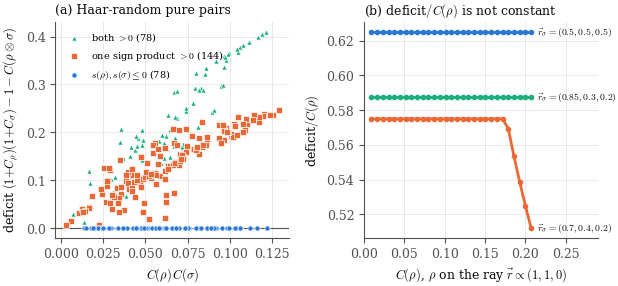

In [24]:
def fig_dichotomy():
    rg_ = np.random.default_rng(2026)
    pts = {'both': [], 'one': [], 'two': []}
    while sum(len(v) for v in pts.values()) < 300:
        a, b = rg_.normal(size=3), rg_.normal(size=3)
        a, b = a / np.linalg.norm(a), b / np.linalg.norm(b)
        ca, cb = C1closed(a), C1closed(b)
        if ca < 1e-3 or cb < 1e-3:
            continue
        D = (1 + ca) * (1 + cb) - 1 - M2.C(np.kron(bloch(a), bloch(b)))
        key = ['both', 'one', 'two'][int(s_of(a) > 0) + int(s_of(b) > 0)]
        pts[key].append((ca * cb, D))
    sigmas = [np.array([.5, .5, .5]), np.array([.7, .4, .2]), np.array([.85, .3, .2])]
    ray = {}
    for sg in sigmas:
        xs, ys = [], []
        for rad in np.linspace(0.72, 1.0, 29):
            r = np.array([rad, rad, 0]) / np.sqrt(2); cr = C1closed(r)
            if cr < 1e-6:
                continue
            D = (1 + cr) * (1 + C1closed(sg)) - 1 - M2.C(np.kron(bloch(r), bloch(sg)))
            xs.append(cr); ys.append(D / cr)
        ray[tuple(sg)] = (xs, ys)

    fig, (ax, bx) = plt.subplots(1, 2, figsize=(7.0, 2.8), gridspec_kw={'wspace': 0.32})
    lab = {'both': r'$s(\rho),s(\sigma)\leq0$', 'one': r'one sign product $>0$', 'two': r'both $>0$'}
    for key, c, mk in [('two', AQUA, '^'), ('one', ORANGE, 's'), ('both', BLUE, 'o')]:
        arr = np.array(pts[key])
        ax.scatter(arr[:, 0], arr[:, 1], s=14, marker=mk, color=c, edgecolor='white', linewidth=0.5,
                   label=f'{lab[key]} ({len(arr)})', zorder=3)
    ax.axhline(0, color=MUTED, lw=0.8, zorder=2)
    ax.set_xlabel(r'$C(\rho)\,C(\sigma)$')
    ax.set_ylabel(r'deficit $(1{+}C_\rho)(1{+}C_\sigma)-1-C(\rho\otimes\sigma)$')
    ax.set_title('(a) Haar-random pure pairs', fontsize=9, loc='left', color=INK)
    ax.legend(fontsize=7, loc='upper left')
    for sg, c in zip(sigmas, [BLUE, ORANGE, AQUA]):
        xs, ys = ray[tuple(sg)]
        bx.plot(xs, ys, color=c, marker='o', ms=3)
        bx.annotate(r'$\vec r_\sigma=(%.2g,%.2g,%.2g)$' % tuple(sg), (xs[-1], ys[-1]), xytext=(4, 0),
                    textcoords='offset points', fontsize=7, color=INK, va='center')
    bx.set_xlabel(r'$C(\rho)$, $\rho$ on the ray $\vec r\propto(1,1,0)$')
    bx.set_ylabel(r'deficit$/C(\rho)$')
    bx.set_title(r'(b) deficit$/C(\rho)$ is not constant', fontsize=9, loc='left', color=INK)
    bx.set_xlim(0, 0.29)
    save(fig, 'fig_dichotomy')

    zero = {k: sum(abs(d) < 1e-8 for _, d in v) for k, v in pts.items()}
    FIGNUM['fig1'] = {k: (len(v), zero[k]) for k, v in pts.items()}
    check("Fig 1(a): zero deficit on every s<=0 pair and on no other pair",
          zero['both'] == len(pts['both']) and zero['one'] == zero['two'] == 0,
          f"s<=0: {zero['both']}/{len(pts['both'])}; others: {zero['one'] + zero['two']}/{len(pts['one']) + len(pts['two'])}")
    xs, ys = ray[(.7, .4, .2)]
    check("Fig 1(b): D/C(rho) for r_sigma=(.7,.4,.2) runs from 0.575 down to 0.5121",
          close(ys[0], 0.575, 1e-6) and close(ys[-1], 0.5121320, 1e-6), f"{ys[0]:.4f} -> {ys[-1]:.4f}")
    return fig

if MAKE_FIGURES:
    fig = fig_dichotomy()

### Figure 2 (`fig_circuits.pdf`): preparation circuits
Drawn with matplotlib (no LaTeX installation needed). Sized for one column (`width=\columnwidth`).

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


   wrote figures/fig_circuits.pdf
[PASS] Fig 2: the three circuits prepare the Ry, Rx and Bell+Rz states


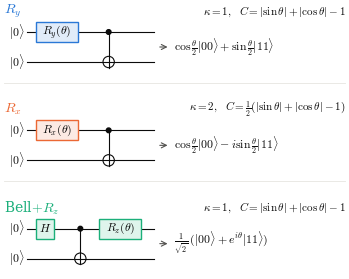

In [25]:
def fig_circuits():
    # 3 data units per inch, so aspect is 1:1 and circles stay round
    W_IN, H_IN = 3.45, 2.75
    fig = plt.figure(figsize=(W_IN, H_IN))
    ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 3 * W_IN); ax.set_ylim(0, 3 * H_IN)
    ax.axis('off'); ax.set_aspect('equal')
    x0, x1 = 0.75, 4.55              # wire extent
    gap = 0.9                        # vertical distance between the two wires of a row

    def wire(y): ax.plot([x0, x1], [y, y], color=INK, lw=0.8, zorder=1)
    def gate(x, y, label, c, w=1.25):
        tint = 0.86 * np.ones(3) + 0.14 * np.array(matplotlib.colors.to_rgb(c))   # opaque light tint
        ax.add_patch(Rectangle((x - w / 2, y - 0.3), w, 0.6, facecolor=tint, edgecolor=c, lw=1.0, zorder=3))
        ax.text(x, y, label, ha='center', va='center', fontsize=8.5, color=INK, zorder=4)
    def cnot(x, yc, yt):
        ax.plot([x, x], [yt - 0.17, yc], color=INK, lw=0.8, zorder=2)
        ax.add_patch(Circle((x, yc), 0.07, color=INK, zorder=4))
        ax.add_patch(Circle((x, yt), 0.17, facecolor='white', edgecolor=INK, lw=0.8, zorder=3))
        ax.plot([x - 0.17, x + 0.17], [yt, yt], color=INK, lw=0.8, zorder=4)
        ax.plot([x, x], [yt - 0.17, yt + 0.17], color=INK, lw=0.8, zorder=4)

    rows = [
        ('Ry', [('g', 1.65, r'$R_y(\theta)$'), ('cx', 3.2)],
         r'$\cos\frac{\theta}{2}|00\rangle+\sin\frac{\theta}{2}|11\rangle$',
         r'$\kappa=1,\ \ C=|\sin\theta|+|\cos\theta|-1$'),
        ('Rx', [('g', 1.65, r'$R_x(\theta)$'), ('cx', 3.2)],
         r'$\cos\frac{\theta}{2}|00\rangle-i\sin\frac{\theta}{2}|11\rangle$',
         r'$\kappa=2,\ \ C=\frac{1}{2}(|\sin\theta|+|\cos\theta|-1)$'),
        ('BRz', [('g', 1.3, r'$H$', 0.55), ('cx', 2.35), ('g', 3.55, r'$R_z(\theta)$')],
         r'$\frac{1}{\sqrt{2}}\,(|00\rangle+e^{i\theta}|11\rangle)$',
         r'$\kappa=1,\ \ C=|\sin\theta|+|\cos\theta|-1$'),
    ]
    ytop = 3 * H_IN - 0.9
    for k, (fam_, ops, state, kc) in enumerate(rows):
        y1 = ytop - 2.95 * k; y2 = y1 - gap; c = COL[fam_]
        ax.text(0.05, y1 + 0.62, NAME[fam_], ha='left', va='center', fontsize=10, color=c)
        ax.text(3 * W_IN - 0.05, y1 + 0.62, kc, ha='right', va='center', fontsize=8, color=INK)
        for y in (y1, y2):
            wire(y); ax.text(x0 - 0.08, y, r'$|0\rangle$', ha='right', va='center', fontsize=8.5, color=INK)
        for op in ops:
            if op[0] == 'g':
                gate(op[1], y1, op[2], c, *(op[3:] if len(op) > 3 else ()))
            else:
                cnot(op[1], y1, y2)
        ax.annotate('', xy=(x1 + 0.5, (y1 + y2) / 2), xytext=(x1 + 0.1, (y1 + y2) / 2),
                    arrowprops=dict(arrowstyle='->', color=MUTED, lw=0.8))
        ax.text(x1 + 0.6, (y1 + y2) / 2, state, ha='left', va='center', fontsize=8.5, color=INK)
        if k < 2:
            ax.plot([0.05, 3 * W_IN - 0.05], [y2 - 0.62, y2 - 0.62], color='#e6e5e1', lw=0.6)
    save(fig, 'fig_circuits')
    # the three circuits prepare the stated states (global phase aside)
    CX = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=complex)
    th = 0.9; e0 = np.array([1, 0, 0, 0], dtype=complex)
    Ry_ = lambda t: np.cos(t/2) * I2 - 1j * np.sin(t/2) * Y
    Rx_ = lambda t: np.cos(t/2) * I2 - 1j * np.sin(t/2) * X
    Rz_ = lambda t: np.cos(t/2) * I2 - 1j * np.sin(t/2) * Z
    outs = {'Ry': CX @ np.kron(Ry_(th), I2) @ e0, 'Rx': CX @ np.kron(Rx_(th), I2) @ e0,
            'BRz': np.kron(Rz_(th), I2) @ CX @ np.kron(Hd, I2) @ e0}
    check("Fig 2: the three circuits prepare the Ry, Rx and Bell+Rz states",
          all(np.allclose(proj(v), fam(k, th)) for k, v in outs.items()))
    return fig

if MAKE_FIGURES:
    fig = fig_circuits()

### Figure 3 (`fig_logical_bloch.pdf`): the logical Bloch sphere

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


   wrote figures/fig_logical_bloch.pdf
[PASS] Fig 3: the drawn logical Bloch curves match <X_L>, <Y_L>, <Z_L> of the three families


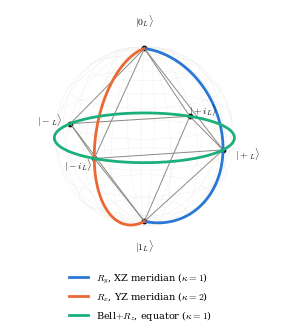

In [26]:
def fig_logical_bloch():
    fig = plt.figure(figsize=(3.6, 3.6)); ax = fig.add_subplot(111, projection='3d')
    ax.computed_zorder = False   # draw in call order: sphere, octahedron, then the three curves on top
    u, v = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]; u = u + np.pi / 40   # keep grid lines off the drawn curves
    ax.plot_wireframe(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v), color='#ebeae6', lw=0.25,
                      rstride=2, cstride=2, zorder=0)
    V = {'0': (0, 0, 1), '1': (0, 0, -1), '+': (1, 0, 0), '-': (-1, 0, 0), '+i': (0, 1, 0), '-i': (0, -1, 0)}
    for a, b in [('0', '+'), ('0', '-'), ('0', '+i'), ('0', '-i'), ('1', '+'), ('1', '-'), ('1', '+i'),
                 ('1', '-i'), ('+', '+i'), ('+i', '-'), ('-', '-i'), ('-i', '+')]:
        ax.plot(*np.array([V[a], V[b]]).T, color=GREY, lw=0.7)
    tt = np.linspace(0.01, np.pi - 0.01, 200)
    # logical Bloch vectors: Ry (sin t, 0, cos t); Rx (0, -sin t, cos t); Bell+Rz (cos t, sin t, 0)
    ax.plot(np.sin(tt), 0 * tt, np.cos(tt), color=BLUE, lw=2, label=r'$R_y$, XZ meridian ($\kappa=1$)')
    ax.plot(0 * tt, -np.sin(tt), np.cos(tt), color=ORANGE, lw=2, label=r'$R_x$, YZ meridian ($\kappa=2$)')
    ph = np.linspace(0, 2 * np.pi, 300)
    ax.plot(np.cos(ph), np.sin(ph), 0 * ph, color=AQUA, lw=2, label=r'Bell$+R_z$, equator ($\kappa=1$)')
    for k_, p in V.items():
        ax.scatter(*p, color=INK, s=10)
        ax.text(*(1.3 * np.array(p)), r'$|%s_L\rangle$' % k_, fontsize=7, color=INK, ha='center', va='center')
    ax.set_box_aspect((1, 1, 1), zoom=1.25); ax.set_axis_off(); ax.view_init(16, -58)
    ax.legend(fontsize=7, loc='upper center', bbox_to_anchor=(0.5, 0.06))
    save(fig, 'fig_logical_bloch')
    XL2, YL2, ZL2 = logical_ops(2); t = 0.8
    lb = lambda r: np.array([np.trace(L @ r).real for L in (XL2, YL2, ZL2)])
    check("Fig 3: the drawn logical Bloch curves match <X_L>, <Y_L>, <Z_L> of the three families",
          np.allclose(lb(fam('Ry', t)), [np.sin(t), 0, np.cos(t)]) and
          np.allclose(lb(fam('Rx', t)), [0, -np.sin(t), np.cos(t)]) and
          np.allclose(lb(fam('BRz', t)), [np.cos(t), np.sin(t), 0]))
    return fig

if MAKE_FIGURES:
    fig = fig_logical_bloch()

### Figure 4 (`fig_wigner_ry.pdf`, `fig_wigner_rx.pdf`): two-qubit Wigner functions at $\theta=\pi/3$
Rows are the first qubit's phase point $(q_1,p_1)$, columns the second's $(q_2,p_2)$, both in the order
$(0,0),(0,1),(1,0),(1,1)$, as stated in Section 6. Negative entries have a dark border. The two panels share
one colour scale; they are separate files because the paper places them side by side at `0.48\columnwidth`.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


   wrote figures/fig_wigner_ry.pdf
   wrote figures/fig_wigner_rx.pdf
[PASS] Fig 4: 4 negative entries for Ry and 2 for Rx at theta = pi/3; values match the 8W matrices of Eq. (31)


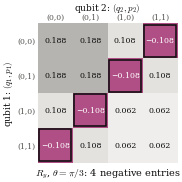

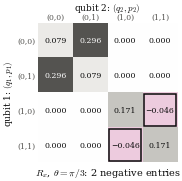

In [27]:
WCMAP = LinearSegmentedColormap.from_list('wig', ['#9c2a6a', '#e7b8d2', '#ffffff', '#d9d8d3', '#52514e'])

def fig_wigner(kind, th=np.pi/3, vmax=0.30):
    Wm = M2.W(fam(kind, th)).reshape(4, 4)
    fig, ax = plt.subplots(figsize=(1.8, 1.95))   # drawn at print size: 0.48\columnwidth
    ax.imshow(Wm, cmap=WCMAP, norm=TwoSlopeNorm(vmin=-0.125, vcenter=0, vmax=vmax))   # -1/8 is the two-qubit minimum
    ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
    for i in range(4):
        for j in range(4):
            v = Wm[i, j]
            ax.text(j, i, f'{v:.3f}'.replace('-', '\u2212'), ha='center', va='center', fontsize=5.6,
                    color='white' if (v > 0.22 or v < -0.075) else INK)
            if v < -1e-12:
                ax.add_patch(Rectangle((j - .46, i - .46), .92, .92, fill=False, edgecolor=INK, lw=1.1))
    ticks = ['(0,0)', '(0,1)', '(1,0)', '(1,1)']
    ax.set_xticks(range(4), ticks, fontsize=5.5); ax.set_yticks(range(4), ticks, fontsize=5.5)
    ax.tick_params(length=0); ax.xaxis.set_ticks_position('top'); ax.xaxis.set_label_position('top')
    ax.set_xlabel(r'qubit 2: $(q_2,p_2)$', fontsize=6.5, labelpad=2); ax.set_ylabel(r'qubit 1: $(q_1,p_1)$', fontsize=6.5, labelpad=2)
    ax.tick_params(pad=1.5)
    nneg = int((Wm < -1e-12).sum())
    ax.set_title(NAME[kind] + r', $\theta=\pi/3$: %d negative entries' % nneg, fontsize=7,
                 color=INK, y=-0.15)
    save(fig, 'fig_wigner_' + kind.lower())
    return fig, Wm

if MAKE_FIGURES:
    fig_ry, Wry = fig_wigner('Ry')
    fig_rx, Wrx = fig_wigner('Rx')
    check("Fig 4: 4 negative entries for Ry and 2 for Rx at theta = pi/3; values match the 8W matrices of Eq. (31)",
          (Wry < -1e-12).sum() == 4 and (Wrx < -1e-12).sum() == 2 and
          np.allclose(8 * Wry, [[1.5, 1.5, 3**.5/2, -3**.5/2], [1.5, 1.5, -3**.5/2, 3**.5/2],
                                [3**.5/2, -3**.5/2, .5, .5], [-3**.5/2, 3**.5/2, .5, .5]]))

### Figure 5 (`fig_kappa_nb.pdf`): $C$, $\Gamma-1$ and $\kappa$ for $R_y$ and $R_x$ (Theorem 6.2)
Curves are the closed forms; dots are exact LP values.

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


   wrote figures/fig_kappa_nb.pdf
[PASS] Fig 5: LP dots agree with the closed forms  —  max deviation 1.1e-15


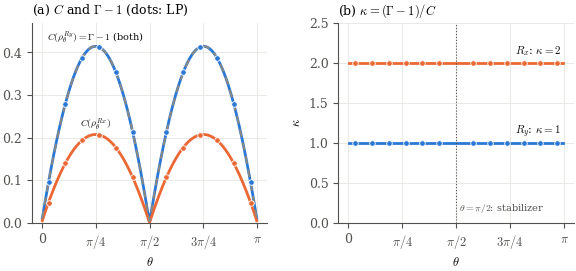

In [28]:
def fig_kappa():
    th = np.linspace(0.01, np.pi - 0.01, 400)
    base = np.abs(np.sin(th)) + np.abs(np.cos(th)) - 1
    thd = np.linspace(0.1, np.pi - 0.1, 13); thd = thd[np.abs(thd - np.pi / 2) > 0.05]
    lp = {k: [(M2.C(fam(k, t)), M2.Gamma(fam(k, t))) for t in thd] for k in ('Ry', 'Rx')}
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(7.0, 2.6), gridspec_kw={'wspace': 0.3})
    ax.plot(th, base, color=BLUE)
    ax.plot(th, base / 2, color=ORANGE)
    ax.plot(th, base, color=GREY, ls=(0, (4, 3)), lw=1.4)
    for k, c in (('Ry', BLUE), ('Rx', ORANGE)):
        ax.scatter(thd, [v[0] for v in lp[k]], s=16, color=c, edgecolor='white', lw=0.6, zorder=4)
    xt = ([0, np.pi / 4, np.pi / 2, 3 * np.pi / 4, np.pi], ['0', r'$\pi/4$', r'$\pi/2$', r'$3\pi/4$', r'$\pi$'])
    ax.set_xticks(*xt); ax.set_xlabel(r'$\theta$')
    ax.set_title(r'(a) $C$ and $\Gamma-1$ (dots: LP)', fontsize=9, loc='left')
    ax.annotate(r'$C(\rho^{Ry}_\theta)=\Gamma-1$ (both)', (np.pi/4, 0.414), xytext=(0, 4),
                textcoords='offset points', ha='center', fontsize=7, color=INK)
    ax.annotate(r'$C(\rho^{Rx}_\theta)$', (np.pi/4, 0.207), xytext=(0, 5), textcoords='offset points',
                ha='center', fontsize=7, color=INK)
    ax.set_ylim(0, 0.47)
    keep = np.abs(th - np.pi / 2) > 0.02
    for k, c, val in (('Ry', BLUE, 1), ('Rx', ORANGE, 2)):
        bx.plot(th[keep], np.full(keep.sum(), val), color=c)
        bx.scatter(thd, [(g - 1) / cc for cc, g in lp[k]], s=16, color=c, edgecolor='white', lw=0.6, zorder=4)
        bx.annotate(NAME[k] + (r': $\kappa=%d$' % val), (np.pi, val), xytext=(-2, 6), textcoords='offset points',
                    ha='right', fontsize=8, color=INK)
    bx.axvline(np.pi / 2, color=MUTED, lw=0.8, ls=':')
    bx.text(np.pi / 2, 0.15, r' $\theta=\pi/2$: stabilizer', fontsize=7, color=MUTED)
    bx.set_ylim(0, 2.5); bx.set_xticks(*xt)
    bx.set_xlabel(r'$\theta$'); bx.set_ylabel(r'$\kappa$')
    bx.set_title(r'(b) $\kappa=(\Gamma-1)/C$', fontsize=9, loc='left')
    save(fig, 'fig_kappa_nb')
    dev = max(max(abs(cc - (abs(np.sin(t)) + abs(np.cos(t)) - 1) / (2 if k == 'Rx' else 1)),
                  abs(g - (abs(np.sin(t)) + abs(np.cos(t))))) for k in lp for t, (cc, g) in zip(thd, lp[k]))
    check("Fig 5: LP dots agree with the closed forms", dev < 1e-8, f"max deviation {dev:.1e}")
    return fig

if MAKE_FIGURES:
    fig = fig_kappa()

### Figure 6 (`fig_noise_nb.pdf`): depolarizing noise at $\theta=\pi/3$ (Section 6.7)

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


   wrote figures/fig_noise_nb.pdf
[PASS] Fig 6: p_c = 0.4226, kappa(Rx) = 2 throughout, kappa(Ry) rises from 1 to 3/2 (reached by p ≈ 0.16)  —  p_c = 0.4226, kappa(Ry) = 3/2 from p = 0.160


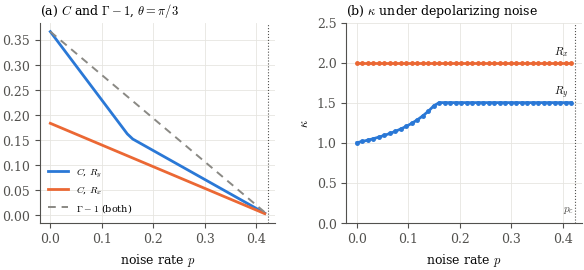

In [29]:
def fig_noise():
    t0 = np.pi / 3; sc = np.sin(t0) + np.cos(t0); pc = (sc - 1) / (sc - 0.5)
    ps = np.linspace(0, pc * 0.985, 40)
    noise = {k: [] for k in ('Ry', 'Rx')}
    for k in noise:
        for p in ps:
            r = (1 - p) * fam(k, t0) + p * np.eye(4) / 4
            noise[k].append((M2.C(r), M2.Gamma(r) - 1))
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(7.0, 2.6), gridspec_kw={'wspace': 0.3})
    for k in noise:
        ax.plot(ps, [v[0] for v in noise[k]], color=COL[k], label=r'$C$, ' + NAME[k])
    ax.plot(ps, [v[1] for v in noise['Ry']], color=GREY, ls=(0, (4, 3)), lw=1.4, label=r'$\Gamma-1$ (both)')
    ax.set_xlabel(r'noise rate $p$'); ax.set_title(r'(a) $C$ and $\Gamma-1$, $\theta=\pi/3$', fontsize=9, loc='left')
    ax.legend(fontsize=7)
    for k in noise:
        kap = [g / c for c, g in noise[k]]
        bx.plot(ps, kap, color=COL[k], marker='o', ms=2.5)
        bx.annotate(NAME[k], (ps[-1], kap[-1]), xytext=(-2, 6), textcoords='offset points', ha='right',
                    fontsize=8, color=INK)
    for ax_ in (ax, bx):
        ax_.axvline(pc, color=MUTED, lw=0.8, ls=':')
    bx.text(pc, 0.15, r'$p_c$ ', ha='right', fontsize=8, color=MUTED)
    bx.set_ylim(0, 2.5); bx.set_xlabel(r'noise rate $p$'); bx.set_ylabel(r'$\kappa$')
    bx.set_title(r'(b) $\kappa$ under depolarizing noise', fontsize=9, loc='left')
    save(fig, 'fig_noise_nb')
    kx = np.array([g / c for c, g in noise['Rx']]); ky = np.array([g / c for c, g in noise['Ry']])
    p15 = float(ps[np.argmax(ky > 1.5 - 1e-6)])
    FIGNUM['fig6'] = {'p_c': pc, 'p_where_kappa_Ry_reaches_1.5': p15}
    check("Fig 6: p_c = 0.4226, kappa(Rx) = 2 throughout, kappa(Ry) rises from 1 to 3/2 (reached by p ≈ 0.16)",
          close(pc, 0.4226, 1e-4) and np.allclose(kx, 2, atol=1e-6) and close(ky[0], 1, 1e-6)
          and close(ky[-1], 1.5, 1e-6) and 0.14 < p15 < 0.17, f"p_c = {pc:.4f}, kappa(Ry) = 3/2 from p = {p15:.3f}")
    return fig

if MAKE_FIGURES:
    fig = fig_noise()

### Figure 7 (`fig_pca_nb.pdf`): PCA of the 16-dimensional Wigner vectors

'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


   wrote figures/fig_pca_nb.pdf


[PASS] Fig 7: the stars mark the most magic point theta = pi/4 of each family (C maximal on (0, pi/2))


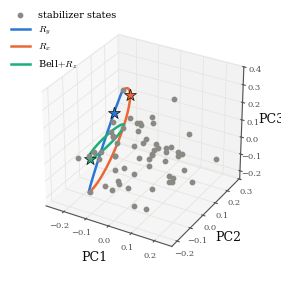

In [30]:
def fig_pca():
    mean = M2.Ws.mean(0)
    _, _, Vt = np.linalg.svd(M2.Ws - mean, full_matrices=False); B = Vt[:3].T
    pca = lambda w: (w - mean) @ B
    fig = plt.figure(figsize=(4.2, 3.6)); ax = fig.add_subplot(111, projection='3d')
    ax.scatter(*pca(M2.Ws).T, s=10, color=GREY, depthshade=False, label='stabilizer states')
    tt = np.linspace(0.01, np.pi - 0.01, 200)
    for k in ('Ry', 'Rx', 'BRz'):
        ts = np.linspace(0, 2 * np.pi, 400) if k == 'BRz' else tt
        O = np.array([pca(M2.W(fam(k, t))) for t in ts])
        ax.plot(*O.T, color=COL[k], lw=1.8, label=NAME[k])
        ax.scatter(*pca(M2.W(fam(k, np.pi / 4))), marker='*', s=80, color=COL[k], edgecolor=INK, lw=0.5, zorder=5)
    ax.set_xlabel('PC1', labelpad=-3); ax.set_ylabel('PC2', labelpad=-3); ax.set_zlabel('PC3', labelpad=-5)
    ax.set_box_aspect((1, 1, 0.9), zoom=0.85)
    ax.tick_params(labelsize=6, pad=-2); ax.legend(fontsize=7, loc='upper left')
    save(fig, 'fig_pca_nb')
    tq = np.linspace(0.05, np.pi / 2 - 0.05, 40)
    check("Fig 7: the stars mark the most magic point theta = pi/4 of each family (C maximal on (0, pi/2))",
          all(abs(tq[np.argmax([M2.C(fam(k, t)) for t in tq])] - np.pi / 4) < 0.06 for k in ('Ry', 'Rx', 'BRz')))
    return fig

if MAKE_FIGURES:
    fig = fig_pca()

### Figure files written

In [31]:
if MAKE_FIGURES:
    for f in sorted(os.listdir(FIGDIR)):
        if f.endswith('.pdf'):
            print(f"   {f:24s} {os.path.getsize(os.path.join(FIGDIR, f)) / 1024:6.1f} kB")
    expected_figs = {'fig_dichotomy', 'fig_circuits', 'fig_logical_bloch', 'fig_wigner_ry', 'fig_wigner_rx',
                     'fig_kappa_nb', 'fig_noise_nb', 'fig_pca_nb'}
    check("all eight figure PDFs written (seven figures; Figure 4 has two panels)",
          expected_figs <= {f[:-4] for f in os.listdir(FIGDIR) if f.endswith('.pdf')})

   fig_circuits.pdf           21.4 kB
   fig_dichotomy.pdf          31.5 kB
   fig_kappa_nb.pdf           24.4 kB
   fig_logical_bloch.pdf      31.1 kB
   fig_noise_nb.pdf           23.5 kB
   fig_pca_nb.pdf             18.9 kB
   fig_wigner_rx.pdf          17.9 kB
   fig_wigner_ry.pdf          17.8 kB
[PASS] all eight figure PDFs written (seven figures; Figure 4 has two panels)


## 14. Ledger

In [32]:
npass = sum(ok for _, ok, _ in LEDGER)
print(f"{npass} / {len(LEDGER)} checks passed   (RUN_N4={RUN_N4}, RUN_SLOW={RUN_SLOW}, MAKE_FIGURES={MAKE_FIGURES}, "
      f"total {time.time()-T0:.0f}s)\n")
for name, ok, detail in LEDGER:
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

143 / 143 checks passed   (RUN_N4=True, RUN_SLOW=True, MAKE_FIGURES=True, total 1123s)

PASS  number of 1-qubit stabilizer states = 6
PASS  number of 2-qubit stabilizer states = 60
PASS  number of 3-qubit stabilizer states = 1080
PASS  number of 4-qubit stabilizer states = 36720
PASS  M_1 = 1
PASS  M_2 = 2 (attained by Bell states)
PASS  M_3 = 5/2
PASS  M_4 = 4
PASS  Wigner factorization: W_{Bell⊗Bell} = W_Bell ⊗ W_Bell
PASS  Section 3.1: M_{n+m} >= M_n M_m, e.g. ||W_{Bell⊗Bell}||_1 = 4 = M_2^2
PASS  Section 2.4: Bell-state Wigner entries reach -1/8, so W_free(2) is not inside the orthant
PASS  Lemma 4.7: every single-qubit stabilizer Wigner vector has entries in {0, 1/2}
PASS  Thm 3.2(i): C vanishes on stabilizer mixtures, e.g. C(I/4) = 0 and C(random mixture) = 0
PASS  eigenvalues of a two-qubit A_alpha are -1/2, -1/2, (2-√3)/2, (2+√3)/2
PASS  Prop C.1(2): -1/8 <= W <= (2+√3)/8 on 20,000 random pure states
PASS  Prop C.1(3): sum W^2 = 1/4 for pure states
PASS  Appendix C: random pure